In [1]:
### Trying to get a separate sense of
### <Political Compass Distance Like Party/Politican Factor> vs <Competence/Valence Like Party/Politician Factor>



### (1) Look at slices of like<Party> along political compass axes for different waves
# (where you think the party/voters haven't moved much



In [1]:
%%time
dataset_name = "W30_comb"
df_list = "BES_Panel"

%matplotlib inline 
%run BES_header.py {dataset_name} {df_list}

global BES_label_list, BES_df_list

Toggle code

var_type (12866, 13)
old_new_col_names not loaded
CPU times: total: 18.8 s
Wall time: 1min 4s


In [2]:
pan_dataset_values = pd.read_pickle(BES_small_data_files+"pan_dataset_allr_valuesW19.zip",compression='zip')

from symfit import Poly, variables, parameters, Model, Fit


x, y, z = variables('x, y, z')
c1, c2, c3 = parameters('c1, c2, c3')
# Make a polynomial. Note the `as_expr` to make it symfit friendly.
model_dict = {
    z: Poly( {(1, 0): c1, (0, 1): c2, (0,0):c3 }, x ,y).as_expr()
}
model = Model(model_dict)
print(model)

mask = BES_Panel["likeConW24"].isnull() # stand in for any like<Party>W24 variables - maybe use weights instead?

BES_Panel["likeBrexitPartyW24"] = BES_Panel["likeBrexitPartyW23"]

BES_Panel.loc[mask,"likeBrexitPartyW24"]=np.nan
new_mask = (~mask)&BES_Panel["likeBrexitPartyW24"].isnull()

BES_Panel.loc[new_mask,"likeBrexitPartyW24"]=BES_Panel.loc[new_mask,"likeBrexitPartyW25"]
BES_Panel.loc[~mask,"likeBrexitPartyW24"].isnull().sum()


BES_Panel["likeGrnW24"] = BES_Panel["likeGrnW23"]

BES_Panel.loc[mask,"likeGrnW24"]=np.nan
new_mask = (~mask)&BES_Panel["likeGrnW24"].isnull()

BES_Panel.loc[new_mask,"likeGrnW24"]=BES_Panel.loc[new_mask,"likeGrnW25"]
BES_Panel.loc[~mask,"likeGrnW24"].isnull().sum()


# bit weak, bit shit, it's partial wave, mostly wave 23, some from wave 25


wave_to_date = BES_file_manifest[BES_file_manifest["Only_or_Combined"]=="Only"].set_index("Wave No")["Date_Start"]
wave_to_date[26]="Apr-24"
wave_to_date[27]="May-24"
wave_to_date[28]="Jun-24"
wave_to_date[29]="Jul-24"
wave_to_date[30]="May-25"

wave_to_date = pd.to_datetime(wave_to_date,format="%b-%y")
wave_to_date

max_wave = 30

[z(x, y; c1, c2, c3) = c1*x + c2*y + c3]


In [ ]:
## csv export for Ewan Hoyle

## latest favourability, constituency, weight, id to not screw things up/later crosschecks
## note about signing non-anomyising form!

# BES_Panel[search(BES_Panel,"like.*W30|ptv.*W30|wt_new_W30|pcon.*W30|gorW30|countryW30").index].to_csv(BES_small_data_files+"BESIP_wave_30_favouribility_export_for_Ewan_Hoyle.csv")

In [31]:
search(BES_Panel,"trans|al_scale|lr_scale|immigSelf")

immigSelfW7        30893
immigSelfW8        33496
immigSelfW9        30029
immigSelfW10       30233
immigSelfW11       30953
immigSelfW12        8984
immigSelfW13        1289
immigSelfW14       31062
immigSelfW15       30840
immigSelfW16       37959
immigSelfW17       34365
immigSelfW20       31468
immigSelfW21       30281
immigSelfW22       28113
immigSelfW23       30949
immigSelfW25       30407
cwTransW25         30407
discrimTransW25    30407
immigSelfW26       30064
immigSelfW27       30445
discrimTransW27     7515
immigSelfW28       31582
immigSelfW29       31098
immigSelfW30       30342
cwTransW30         30342
discrimTransW30     7564
cwTransW26W27      32395
lr_scaleW1_W5      38563
al_scaleW1_W5      37947
lr_scaleW6         27818
al_scaleW6         27287
lr_scaleW7_W9      36465
al_scaleW7_W9      35867
lr_scaleW10_W12    30349
al_scaleW10_W12    30085
lr_scaleW13        28061
al_scaleW13        27248
lr_scaleW14W15     32384
al_scaleW14W15     31628
lr_scaleW16        33450


In [33]:
cwTransW30 = BES_Panel["cwTransW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)
discrimTransW30 = BES_Panel["discrimTransW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)
immigSelfW30 = BES_Panel["immigSelfW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)
lr_scaleW30 = BES_Panel["lr_scaleW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)
al_scaleW30 = BES_Panel["al_scaleW30"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)

print( lr_scaleW30.corr(cwTransW30),al_scaleW30.corr(cwTransW30) )
print( lr_scaleW30.corr(discrimTransW30),al_scaleW30.corr(discrimTransW30) )
print( lr_scaleW30.corr(immigSelfW30),al_scaleW30.corr(immigSelfW30) )

-0.22565860203743934 -0.41782028612122013
-0.24593156829100948 -0.3561186724385303
-0.18156040606057797 -0.60677377578294


In [34]:
BES_Panel["discrimTransW30"]

id
1                                     NaN
2                                     NaN
3                                     NaN
4                                     NaN
5                                     NaN
                       ...               
123795    A lot of discrimination against
123796                                NaN
123797                                  1
123798                                NaN
123799                                NaN
Name: discrimTransW30, Length: 122372, dtype: category
Categories (12, object): ['A lot of discrimination in favour' < '1' < '2' < '3' ... '8' < '9' < 'A lot of discrimination against' < 'Don't know']

In [5]:
search(BES_Panel,"ageW8|p_eurefvote|wt_new_W8")

wt_new_W8            33496
likeFarageW8         33496
ageW8                33496
p_education_ageW8    33145
p_eurefvote          84445
dtype: int64

In [8]:
(BES_Panel["ageW8"].astype('float')*BES_Panel["wt_new_W8"]).groupby(BES_Panel["p_eurefvote"]).mean()

p_eurefvote
I voted to remain    40.521200
I voted to leave     48.861856
Don't know           62.982892
dtype: float64

In [12]:
temp = BES_Panel[["ageW8","wt_new_W8","p_eurefvote"]]
temp["ageW8"] = temp["ageW8"].astype(float)
temp["p_eurefvote"] = temp["p_eurefvote"].replace("Don't know",np.nan)

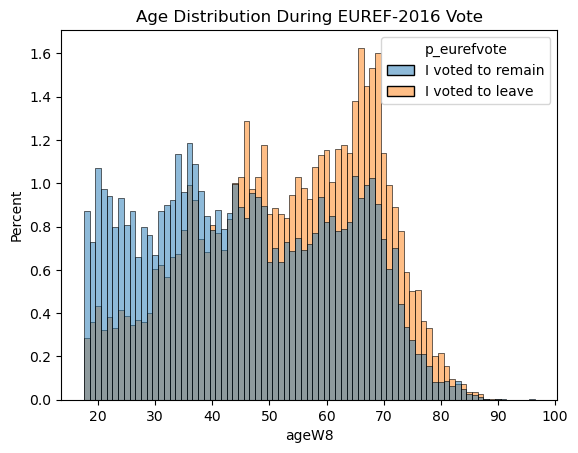

In [20]:
sns.histplot(data=temp, x="ageW8", weights="wt_new_W8", hue='p_eurefvote', kde=False,discrete=True, stat="percent")
plt.title("Age Distribution During EUREF-2016 Vote");

In [3]:
search(BES_Panel,"immigEcon")

immigEconW1     30182
immigEconW2     30885
immigEconW3     28560
immigEconW4     31548
immigEconW7     30893
immigEconW8     33496
immigEconW10    30233
immigEconW11    30953
immigEconW13    31131
immigEconW14    31062
immigEconW15    30840
immigEconW16    37959
immigEconW17    34365
immigEconW20    31468
immigEconW21    30281
immigEconW22    28113
immigEconW23    30949
immigEconW24     2577
immigEconW25    30407
immigEconW26    30064
immigEconW27    30445
immigEconW30    30342
dtype: int64

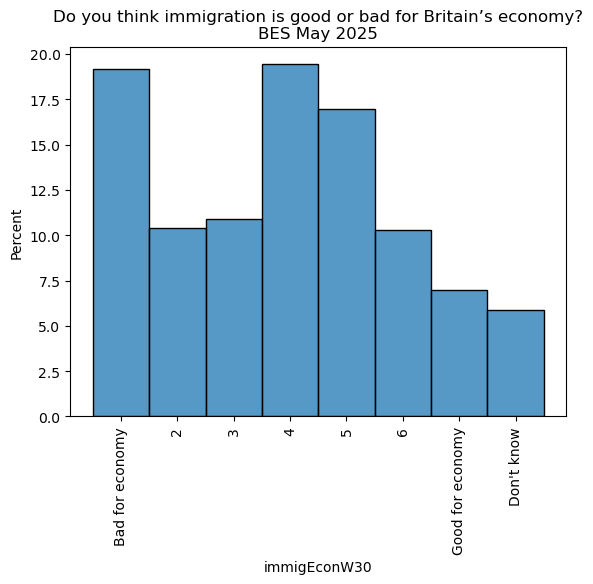

In [11]:
sns.histplot(data = BES_Panel, x="immigEconW30",weights="wt_new_W30",bins=8,stat='percent');
plt.xticks(rotation=90);
plt.title("Do you think immigration is good or bad for Britain’s economy?\nBES May 2025");

In [6]:
BES_Panel["immigEconW30"].value_counts()

immigEconW30
4                   5979
Bad for economy     5625
5                   5429
6                   3371
3                   3220
2                   3130
Good for economy    2188
Don't know          1400
Name: count, dtype: int64

In [304]:
## go from waves to value_set

In [4]:
# make one big dataframe

df = pd.DataFrame()

sample_size_threshold = 1000 # for like_ptv_gaps, early waves don't overlap the questions much

scales = ["al_scale","lr_scale"]
parties = ["Con","Lab","LD","BrexitParty","UKIP","SNP","PC","Grn","TIG","BNP","DUP"]

scale_vars = search(BES_Panel,"|".join(scales)).index

df[scale_vars] = BES_Panel[scale_vars].apply(lambda x: x.cat.codes.replace(-1,np.nan))

vote_simply_dict = {'Conservative':"CON", 'Labour':"LAB", "Don't know":np.nan, 'Liberal Democrat':"LD",
       'United Kingdom Independence Party (UKIP)':"UKIP", 'I would/did not vote':np.nan,
       'Green Party':"GP", 'Scottish National Party (SNP)':np.nan,
       'Brexit Party/Reform UK':"BrexitParty", 'Other':np.nan, 'Plaid Cymru':np.nan,
       'An independent candidate':np.nan, 'British National Party (BNP)':np.nan,
       'Change UK- The Independent Group':np.nan}
df[ search(BES_Panel,"generalElectionVoteW\d+").index ] = BES_Panel[ search(BES_Panel,"generalElectionVoteW\d+").index ]\
    .astype('object').apply(lambda x: x.replace(vote_simply_dict))

party_name_replace_dict = {"CON":"Con","LAB":"Lab","LD":"LD","GP":"Grn"}


# for wave in range(1,max_wave+1): 
#     if wave>=15:
#         df["generalElectionVoteW"+str(wave)] = df["generalElectionVoteW"+str(wave)].replace("UKIP",np.nan)
#         temp = pd.get_dummies(df["generalElectionVoteW"+str(wave)].replace(party_name_replace_dict)).astype('float')*10
#         temp.columns = ["VI"+x+"W"+str(wave) for x in temp.columns]
#         df[temp.columns] = temp        
        
#         df["generalElectionVoteW"+str(wave)] = df["generalElectionVoteW"+str(wave)].replace("BrexitParty","REFUK")
        
#     else:
#         df["generalElectionVoteW"+str(wave)] = df["generalElectionVoteW"+str(wave)].replace("BrexitParty",np.nan)

#         temp = pd.get_dummies(df["generalElectionVoteW"+str(wave)].replace(party_name_replace_dict)).astype('float')*10
#         temp.columns = ["VI"+x+"W"+str(wave) for x in temp.columns]
#         df[temp.columns] = temp  

#         df["generalElectionVoteW"+str(wave)] = df["generalElectionVoteW"+str(wave)].replace("UKIP","REFUK")


for wave in range(1,max_wave+1):
    print(wave)
    var_list = [x+"W"+str(wave) for x in scales] + ["like"+x+"W"+str(wave) for x in parties] + ["ptv"+x+"W"+str(wave) for x in parties]
    
    for var in var_list:
        if var in BES_Panel.columns:
            df[var] = BES_Panel[var].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)
            if "Don't know" in BES_Panel[var].unique():
                df[var+"_dk"] = (BES_Panel[var]=="Don't know").astype(float)
                df.loc[BES_Panel[var].isnull(),var+"_dk"] = np.nan
    ### add wts here, one set per wave
    wt_var = search(BES_Panel,"wt_(new|full)_W"+str(wave)+"($|_result)").index[0]
    df["wtW"+str(wave)] = BES_Panel[wt_var]
    for party in parties:
        like_var = "like"+party+"W"+str(wave)
        ptv_var = "ptv"+party+"W"+str(wave)
        like_ptv_gap_var = "like_ptv_gap_"+party+"W"+str(wave)
        if (like_var in BES_Panel.columns) & (ptv_var in BES_Panel.columns):
            df[like_ptv_gap_var] = df[like_var]-df[ptv_var]
            if df[like_ptv_gap_var].notnull().sum()<1000:
                df = df.drop(like_ptv_gap_var,axis=1)            


    ### go through parties, if like and ptv variable in wave, subtract one from other

index_overlap = list(set(BES_Panel.index).intersection(set(pan_dataset_values.index)))


pan_dataset_vars = ["Social: Liberalism(0) <-> Conservatism(200){uniform}","Economic: Left(0) <-> Right(200){uniform}",
                   "Economic: Left <-> Right{gaussian-ish}complete_fully","Social: Liberalism <-> Conservatism{gaussian-ish}complete_fully"]
for var in pan_dataset_vars:
    df[var]=np.nan
    df.loc[index_overlap,var] =     pan_dataset_values.loc[index_overlap,var]
q=11
df["Economic: Left(0) <-> Right(10)"] = pd.qcut(df["Economic: Left <-> Right{gaussian-ish}complete_fully"],q=q).cat.codes.replace(-1,np.nan)
df["Social: Lib(0) <-> Auth(10)"] = pd.qcut(df["Social: Liberalism <-> Conservatism{gaussian-ish}complete_fully"],q=q).cat.codes.replace(-1,np.nan)                



### try adding BESf2f data!

BES_df_list = pd.read_pickle("E:\\BES_analysis_data\\Face_to_face\\BES_df_list.pickle")
f2f_harmonised = pd.read_pickle("E:\\BES_analysis_data\\Face_to_face\\f2f_harmonised_temp.zip", compression='zip')
BES_label_list = pd.read_pickle("E:\\BES_analysis_data\\Face_to_face\\BES_label_list.pickle")
f2f_harmonised_values = pd.read_pickle("E:\\BES_analysis_data\\Face_to_face\\f2f_harmonised_values.zip", compression='zip')
# {k:v for k,v in BES_label_list['1987'].items() if "like" in v.lower() or "prob" in v.lower() or "feel" in v.lower() or "for or against" in v.lower()}
# f2f_harmonised.groupby("dataset")["soc_lib_auth_complete"].apply(lambda x: x.notnull().sum())
# np.unique([x.split("W")[0] for x in df.columns])

# generalElectionVote, like<party>, ptv<party>, like_ptv_gap,  wt, value_sets
## should probably add country!

temp = pd.DataFrame()
# 1987
dataset="1987"

 # 'v13a': 'for or against conservative party',
 # 'v13b': 'for or against labour party',
 # 'v13c': 'for or against social democrats',
 # 'v13d': 'for or against liberal party',
 # 'v13e': 'for or against snp',
 # 'v13f': 'for or against plaid cymru',

# 1 strongly in favour, 5 strong againsts


temp["likeConW"+dataset] = BES_df_list[dataset]["v13a"].replace({8.0:np.nan,9.0:np.nan}).apply(lambda x: 10-((x-1)*2.5))
temp["likeLabW"+dataset] = BES_df_list[dataset]["v13b"].replace({8.0:np.nan,9.0:np.nan}).apply(lambda x: 10-((x-1)*2.5))
temp["likeSDPW"+dataset] = BES_df_list[dataset]["v13c"].replace({8.0:np.nan,9.0:np.nan}).apply(lambda x: 10-((x-1)*2.5))
temp["likeLDW"+dataset] = BES_df_list[dataset]["v13d"].replace({8.0:np.nan,9.0:np.nan}).apply(lambda x: 10-((x-1)*2.5))
# sdp/lib alliance      754 == vote LD
temp["likeSNPW"+dataset] = BES_df_list[dataset]["v13e"].replace({8.0:np.nan,9.0:np.nan}).apply(lambda x: 10-((x-1)*2.5))
temp["likePCW"+dataset] = BES_df_list[dataset]["v13f"].replace({8.0:np.nan,9.0:np.nan}).apply(lambda x: 10-((x-1)*2.5))

temp["generalElectionVoteW"+dataset] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["vote"]
temp['Social: Lib(0) <-> Auth(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["soc_lib_auth_complete"]*20/16
temp['Economic: Left(0) <-> Right(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["ec_left_right_complete"]*20/16
temp['wt'] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["wt"]
temp.index = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["uid"]

df = pd.concat([df,temp],axis=1)


temp = pd.DataFrame()
dataset = "1992"
# 'v14a': 'r feel about the conservative party? q14a',
#  'v14b': 'r feel about the labour party?      q14b',
#  'v14c': 'r feel about the liberal democratic? q14c',
#  'v14d': 'r feel about the green party?       q14d',
#  'v14e': 'r feel about scottish national party? q14e',
#  'v14f': 'r feel about plaid cymru?           q14f',
replace_dict = {'strongly in favour':5.0, 'in      favour':4.0, 'neither':3.0, 'against':2.0,
       'strongly against':1.0, "dk/can't say":np.nan, 'not     answered':np.nan,'skp,not scottish':np.nan,'skp,not welsh':np.nan}

temp["likeConW"+dataset] = BES_df_list[dataset]["v14a"].replace(replace_dict).apply(lambda x: (x-1)*2.5).astype(float)
temp["likeLabW"+dataset] = BES_df_list[dataset]["v14b"].replace(replace_dict).apply(lambda x: (x-1)*2.5).astype(float)
temp["likeLDW"+dataset] = BES_df_list[dataset]["v14c"].replace(replace_dict).apply(lambda x: (x-1)*2.5).astype(float)
temp["likeGrnW"+dataset] = BES_df_list[dataset]["v14d"].replace(replace_dict).apply(lambda x: (x-1)*2.5).astype(float)
temp["likeSNPW"+dataset] = BES_df_list[dataset]["v14e"].replace(replace_dict).apply(lambda x: (x-1)*2.5).astype(float)
temp["likePCW"+dataset] = BES_df_list[dataset]["v14f"].replace(replace_dict).apply(lambda x: (x-1)*2.5).astype(float)

temp["generalElectionVoteW"+dataset] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["vote"]
temp['Social: Lib(0) <-> Auth(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["soc_lib_auth_complete"]*20/16
temp['Economic: Left(0) <-> Right(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["ec_left_right_complete"]*20/16
temp['wt'] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["wt"]
temp.index = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["uid"]
temp.describe()
df = pd.concat([df,temp],axis=1)


temp = pd.DataFrame()
dataset = "1997"
# 1997 
# 'confeel': 'how feel about conservative party? q231',
#  'labfeel': 'how feel about labour party ? q232',
#  'ldfeel': 'how feel about liberal democrat party? q233',

#  'grnfeel': 'how feel about green party? q234',
#  'reffeel': 'how feel about referendum party? q235',

#  'snpfeel': 'how feel about snp [if scotland]? q236',
#  'pcfeel': 'how feel about plaid cymru [if wales]? q237',

 # 'conlike': 'r likes conservative party? q219a',
 # 'lablike': 'r likes the labour party? q219b',
 # 'ldlike': 'r likes the liberal democratic party? q219c',
 # 'snplike': 'r likes scottish national party? q219d',
 # 'pclike': 'r likes plaid cymru? q219e',

replace_dict = {'no self-completion':np.nan,'no self-completn':np.nan, 'strongly dislike':0, 
            '(mid-point)':5,       'strongly like':10,
       "haven't heard of":np.nan,   "can't   choose":np.nan, 'not     answered':np.nan,'skp,eng+wales':np.nan,'skp,eng+scotland':np.nan}

replace_dict2 = {'strongly in favour ':5.0, 'in favour':4.0, 'neither in favour nor against':3.0, 'against':2.0,
       'strongly against':1.0, "don't   know":np.nan, 'not     answered':np.nan,'skp,not scottish':np.nan,'skp,not welsh':np.nan,}
BES_df_list["1997"]['conlike'].replace(replace_dict).astype(float).corr( BES_df_list["1997"]['confeel'].replace(replace_dict2).astype(float) )

pd.crosstab(BES_df_list["1997"]['conlike'].replace(replace_dict).astype(float),BES_df_list["1997"]['confeel'].replace(replace_dict2).astype(float))
# We would like to know what you think about each of our political parties.
# Please rate each party on a scale from 0 to 10, where 0 means that you
# strongly dislike that party and 10 means that you strongly like that party.
# If you come to a party that you haven’t heard of or you don’t feel that
# you know enough about it, please tick one of the boxes on the right.

# Please choose a phrase from this card to say how you feel about the
# Conservative Party? *
# 5 Strongly in favour
# 4 In favour
# 3 Neither in favour nor against
# 2 Against
# 1 Strongly against

temp["likeConW"+dataset] = BES_df_list[dataset]["conlike"].replace(replace_dict).astype(float)
temp["likeLabW"+dataset] = BES_df_list[dataset]["lablike"].replace(replace_dict).astype(float)
temp["likeLDW"+dataset] = BES_df_list[dataset]["ldlike"].replace(replace_dict).astype(float)

temp["likeSNPW"+dataset] = BES_df_list[dataset]["snplike"].replace(replace_dict).astype(float)
temp["likePCW"+dataset]  = BES_df_list[dataset]["pclike"].replace(replace_dict).astype(float)
# the last two are from a different format!
temp["likeGrnW"+dataset] = BES_df_list[dataset]["grnfeel"].replace(replace_dict2).apply(lambda x: (x-1)*2.5).astype(float)
temp["likeRefW"+dataset] = BES_df_list[dataset]["reffeel"].replace(replace_dict2).apply(lambda x: (x-1)*2.5).astype(float)

temp["generalElectionVoteW"+dataset] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["vote"]
temp['Social: Lib(0) <-> Auth(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["soc_lib_auth_complete"]*20/16
temp['Economic: Left(0) <-> Right(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["ec_left_right_complete"]*20/16
temp['wt'] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["wt"]
temp.index = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["uid"]
temp.describe()
df = pd.concat([df,temp],axis=1)

temp = pd.DataFrame()
dataset = "2001"
# 2001
 # 'aq10a': 'feel about labour party',
 # 'aq10b': 'feel about conservative party',
 # 'aq10c': 'feel about liberal democrat party',
 # 'aq10d': 'feel about scottish national party',
 # 'aq10e': 'feel about plaid cymru',

 # 'bq11a': 'feel about labour party(2nd)',
 # 'bq11b': 'feel about conservative party(2nd)',
 # 'bq11c': 'feel about liberal democrat party(2nd)',
 # 'bq11d': 'feel about snp',
 # 'bq11e': 'feel about plaid cymru(2nd)',

# 'cq32a': 'prob vote-conservative',
#  'cq32b': 'prob vote-labour',
#  'cq32c': 'prob vote-liberal democrat',
#  'cq32d': 'prob vote-snp',
#  'cq32e': 'prob vote-plaid cymru'
replace_dict = {'strongly dislike':0, 'very unlikely':0, 'strongly like':10, 'very likely':10, "don't know":np.nan, 'refused':np.nan, 'not app':np.nan, 
                'refused, not app':np.nan,'not ascertainable':np.nan,'no mailback':np.nan, 'not asked/na':np.nan}

temp["likeLabW"+dataset] = BES_df_list[dataset][['aq10a','bq11a']].replace(replace_dict).fillna(axis=1,method='bfill')['aq10a'].astype(float)
temp["likeConW"+dataset] = BES_df_list[dataset][['aq10b','bq11b']].replace(replace_dict).fillna(axis=1,method='bfill')['aq10b'].astype(float)
temp["likeLDW"+dataset]  = BES_df_list[dataset][['aq10c','bq11c']].replace(replace_dict).fillna(axis=1,method='bfill')['aq10c'].astype(float)

temp["likeSNPW"+dataset] = BES_df_list[dataset][['aq10d','bq11d']].replace(replace_dict).fillna(axis=1,method='bfill')['aq10d'].astype(float)
temp["likePCW"+dataset]  = BES_df_list[dataset][['aq10e','bq11e']].replace(replace_dict).fillna(axis=1,method='bfill')['aq10e'].astype(float)

# temp["likeGrnW"+dataset] = BES_df_list[dataset][['aq16d','bq21d']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16d'].astype(float)


temp["ptvConW"+dataset] = BES_df_list[dataset]["cq32a"].replace(replace_dict).astype(float)
temp["ptvLabW"+dataset] = BES_df_list[dataset]["cq32b"].replace(replace_dict).astype(float)
temp["ptvLDW"+dataset] = BES_df_list[dataset]["cq32c"].replace(replace_dict).astype(float)
# temp["likeGrnW"+dataset] = BES_df_list[dataset]["v14d"].replace(replace_dict)
temp["ptvSNPW"+dataset] = BES_df_list[dataset]["cq32d"].replace(replace_dict).astype(float)
temp["ptvPCW"+dataset] = BES_df_list[dataset]["cq32e"].replace(replace_dict).astype(float)

temp["generalElectionVoteW"+dataset] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["vote"]
temp['Social: Lib(0) <-> Auth(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["soc_lib_auth_complete"]*20/16
temp['Economic: Left(0) <-> Right(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["ec_left_right_complete"]*20/16
temp['wt'] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["wt"]
temp.index = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["uid"]
temp.describe()
df = pd.concat([df,temp],axis=1)


# 2005
dataset = "2005"
temp = pd.DataFrame()
 # 'aq16a': 'feelings about labour party',
 # 'aq16b': 'feelings about conservative party',
 # 'aq16c': 'feelings about liberal democrat party',
 # 'aq16d': 'feelings about greens',
 # 'aq16e': 'feelings about ukip',
 # 'aq16f': 'feelings about snp',
 # 'aq16g': 'feelings about plaid cymru',

 # 'bq21a': 'feelings about labour party(3rd)',
 # 'bq21b': 'feelings about conservative party(3rd)',
 # 'bq21c': 'feelings about liberal democrat party(3rd)',
 # 'bq21d': 'feelings about greens(3rd)',
 # 'bq21e': 'feelings about ukip(3rd)',
 # 'bq21f': 'feelings about snp(3rd)',
 # 'bq21g': 'feelings about plaid cymru(3rd)',

 # 'dq24': 'feelings about labour party(4th)',
 # 'dq25': 'feelings about conservative party(4th)',
 # 'dq26': 'feelings about liberal democrat party(4th)',
 # 'dq27': 'feelings about snp(4th)',
 # 'dq28': 'feelings about plaid cymru(4th)',

 # 'cq22a': 'how likely vote conservative',
 # 'cq22b': 'how likely vote labour',
 # 'cq22c': 'how likely vote liberal democrat',
 # 'cq22d': 'how likely vote ukip',
 # 'cq22e': 'how likely vote greens',
 # 'cq22fsc': 'how likely vote snp [scotland]',
 # 'cq22fwa': 'how likely vote pc [wales]',
replace_dict = {999:np.nan,99:np.nan,98:np.nan,12:np.nan}
temp["likeLabW"+dataset] = BES_df_list[dataset][['aq16a','bq21a','dq24']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16a'].astype(float)
temp["likeConW"+dataset] = BES_df_list[dataset][['aq16b','bq21b','dq25']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16b'].astype(float)
temp["likeLDW"+dataset]  = BES_df_list[dataset][['aq16c','bq21c','dq26']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16c'].astype(float)

temp["likeSNPW"+dataset] = BES_df_list[dataset][['aq16f','bq21f','dq27']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16f'].astype(float)
temp["likePCW"+dataset]  = BES_df_list[dataset][['aq16g','bq21g','dq28']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16g'].astype(float)

temp["likeGrnW"+dataset] = BES_df_list[dataset][['aq16d','bq21d']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16d'].astype(float)
temp["likeUKIPW"+dataset]= BES_df_list[dataset][['aq16e','bq21e']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16e'].astype(float)

temp["ptvConW"+dataset] = BES_df_list[dataset]["cq22a"].replace(replace_dict).astype(float)
temp["ptvLabW"+dataset] = BES_df_list[dataset]["cq22b"].replace(replace_dict).astype(float)
temp["ptvLDW"+dataset]  = BES_df_list[dataset]["cq22c"].replace(replace_dict).astype(float)
temp["ptvUKIPW"+dataset]= BES_df_list[dataset]["cq22d"].replace(replace_dict).astype(float)
temp["ptvGrnW"+dataset] = BES_df_list[dataset]["cq22e"].replace(replace_dict).astype(float)
temp["ptvSNPW"+dataset] = BES_df_list[dataset]["cq22fsc"].replace(replace_dict).astype(float)
temp["ptvPCW"+dataset]  = BES_df_list[dataset]["cq22fwa"].replace(replace_dict).astype(float)

temp["generalElectionVoteW"+dataset] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["vote"]
temp['Social: Lib(0) <-> Auth(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["soc_lib_auth_complete"]*20/16
temp['Economic: Left(0) <-> Right(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["ec_left_right_complete"]*20/16
temp['wt'] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["wt"]
temp.index = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["uid"]
# 3 variables asking same q about same party ...
# I *think* pre/during/post campaign waves???
BES_df_list[dataset][['aq16a','bq21a','dq24']].replace(replace_dict).corr(),BES_df_list[dataset][['aq16a','bq21a','dq24']].replace(replace_dict).describe()
temp.describe()

df = pd.concat([df,temp],axis=1)
# BES_df_list[dataset]['cq22a'].replace(replace_dict).value_counts()

# 2010
dataset = "2010"
temp = pd.DataFrame()

 # 'aq16_1': 'feelings-labour party',
 # 'aq16_2': 'feelings-conservative party',
 # 'aq16_3': 'feelings-liberal democrat party',
 # 'aq16_4': 'feelings-green party',
 # 'aq16_5': 'feelings-ukip',
 # 'aq16_6': 'feelings-bnp',
 # 'aq16_7': 'feelings-snp',
 # 'aq16_8': 'feelings-plaid cymru',

 # 'bq17_1': 'feelings-labour party(3rd)',
 # 'bq17_2': 'feelings-conservative party(3rd)',
 # 'bq17_3': 'feelings-liberal democrats',
 # 'bq17_4': 'feelings-green party(3rd)',
 # 'bq17_5': 'feelings-ukip(3rd)',
 # 'bq17_6': 'feelings_bnp',
 # 'bq17_7': 'feelings-snp(3rd)',
 # 'bq17_8': 'feelings-plaid cymru(3rd)',


 # 'cq23_1': 'likely ever vote conservative',
 # 'cq23_2': 'likely ever vote labour',
 # 'cq23_3': 'likely ever vote liberal democrat',
 # 'cq23_4': 'likely ever vote ukip',
 # 'cq23_5': 'likely ever vote green',
 # 'cq23_6': 'likely ever vote bnp',
 # 'cq23_7s': 'likely ever vote snp',
 # 'cq23_7w': 'likely ever vote plaid cymru',
 # 'cq23_7e': 'likely ever vote other party'
replace_dict = {'0-strongly dislike':0, '10-strongly like':10, '0-very unlikely':0,'10-very likely':10}

temp["likeLabW"+dataset] = BES_df_list[dataset][['aq16_1','bq17_1']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16_1'].astype(float)
temp["likeConW"+dataset] = BES_df_list[dataset][['aq16_2','bq17_2']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16_2'].astype(float)
temp["likeLDW"+dataset]  = BES_df_list[dataset][['aq16_3','bq17_3']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16_3'].astype(float)

temp["likeGrnW"+dataset] = BES_df_list[dataset][['aq16_4','bq17_4']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16_4'].astype(float)
temp["likeUKIPW"+dataset]= BES_df_list[dataset][['aq16_5','bq17_5']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16_5'].astype(float)
temp["likeBNPW"+dataset] = BES_df_list[dataset][['aq16_6','bq17_6']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16_6'].astype(float)

temp["likeSNPW"+dataset] = BES_df_list[dataset][['aq16_7','bq17_7']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16_7'].astype(float)
temp["likePCW"+dataset]  = BES_df_list[dataset][['aq16_8','bq17_8']].replace(replace_dict).fillna(axis=1,method='bfill')['aq16_8'].astype(float)

temp["ptvConW"+dataset] = BES_df_list[dataset]["cq23_1"].replace(replace_dict).astype(float)
temp["ptvLabW"+dataset] = BES_df_list[dataset]["cq23_2"].replace(replace_dict).astype(float)
temp["ptvLDW"+dataset]  = BES_df_list[dataset]["cq23_3"].replace(replace_dict).astype(float)
temp["ptvUKIPW"+dataset]= BES_df_list[dataset]["cq23_4"].replace(replace_dict).astype(float)
temp["ptvGrnW"+dataset] = BES_df_list[dataset]["cq23_5"].replace(replace_dict).astype(float)
temp["ptvBNPW"+dataset] = BES_df_list[dataset]["cq23_6"].replace(replace_dict).astype(float)
temp["ptvSNPW"+dataset] = BES_df_list[dataset]["cq23_7s"].replace(replace_dict).astype(float)
temp["ptvPCW"+dataset]  = BES_df_list[dataset]["cq23_7w"].replace(replace_dict).astype(float)
temp["ptvOTHW"+dataset] = BES_df_list[dataset]["cq23_7e"].replace(replace_dict).astype(float)

temp["generalElectionVoteW"+dataset] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["vote"]
temp['Social: Lib(0) <-> Auth(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["soc_lib_auth_complete"]*20/16
temp['Economic: Left(0) <-> Right(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["ec_left_right_complete"]*20/16
temp['wt'] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["wt"]
temp.index = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["uid"]
temp.describe()
# BES_df_list[dataset]['cq23_7e'].replace(replace_dict).astype(float).value_counts()
df = pd.concat([df,temp],axis=1)

# 2015
dataset = "2015"
temp = pd.DataFrame()
# 2015
 # 'cses_q3_1': 'Like/dislike: Conservatives',
 # 'cses_q3_2': 'Like/dislike: Labour',
 # 'cses_q3_3': 'Like/dislike: Liberal Democrats',
 # 'cses_q3_4': 'Like/dislike: UKIP',
 # 'cses_q3_5': 'Like/dislike: Greens',
 # 'cses_q3_6': 'Like/dislike: SNP',
 # 'cses_q3_7': 'Like/dislike: Plaid Cymru',

 # 's01_1': 'Probability of voting for Conservatives',
 # 's01_2': 'Probability of voting for Labour',
 # 's01_3': 'Probability of voting for Liberal Democrats',
 # 's01_4': 'Probability of voting for UKIP',
 # 's01_5': 'Probability of voting for Greens',
 # 's01_6': 'Probability of voting for SNP',
 # 's01_7': 'Probability of voting for Plaid Cymru',
replace_dict = {'Not stated':np.nan, "Don't know":np.nan, '0 Strongly Dislike':0,'0 very unlikely':0, '10 Strongly Like':10,'10 very likely':10,}

temp["likeLabW"+dataset] = BES_df_list[dataset]['cses_q3_2'].replace(replace_dict).astype(float)
temp["likeConW"+dataset] = BES_df_list[dataset]['cses_q3_1'].replace(replace_dict).astype(float)
temp["likeLDW"+dataset]  = BES_df_list[dataset]['cses_q3_3'].replace(replace_dict).astype(float)
temp["likeGrnW"+dataset] = BES_df_list[dataset]['cses_q3_5'].replace(replace_dict).astype(float)
temp["likeUKIPW"+dataset]= BES_df_list[dataset]['cses_q3_4'].replace(replace_dict).astype(float)
temp["likeSNPW"+dataset] = BES_df_list[dataset]['cses_q3_6'].replace(replace_dict).astype(float)
temp["likePCW"+dataset]  = BES_df_list[dataset]['cses_q3_7'].replace(replace_dict).astype(float)

temp["ptvConW"+dataset] = BES_df_list[dataset]["s01_1"].replace(replace_dict).astype(float)
temp["ptvLabW"+dataset] = BES_df_list[dataset]["s01_2"].replace(replace_dict).astype(float)
temp["ptvLDW"+dataset]  = BES_df_list[dataset]["s01_3"].replace(replace_dict).astype(float)
temp["ptvUKIPW"+dataset]= BES_df_list[dataset]["s01_4"].replace(replace_dict).astype(float)
temp["ptvGrnW"+dataset] = BES_df_list[dataset]["s01_5"].replace(replace_dict).astype(float)
temp["ptvSNPW"+dataset] = BES_df_list[dataset]["s01_6"].replace(replace_dict).astype(float)
temp["ptvPCW"+dataset]  = BES_df_list[dataset]["s01_7"].replace(replace_dict).astype(float)

temp["generalElectionVoteW"+dataset] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["vote"]
temp['Social: Lib(0) <-> Auth(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["soc_lib_auth_complete"]*20/16
temp['Economic: Left(0) <-> Right(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["ec_left_right_complete"]*20/16
temp['wt'] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["wt"]
temp.index = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["uid"]
temp.describe()
# BES_df_list[dataset]['cq23_7e'].replace(replace_dict).astype(float).value_counts()
df = pd.concat([df,temp],axis=1)



# 2017
dataset = "2017"
temp = pd.DataFrame()
 # 'q11_cses_1': 'Like/dislike: Conservatives',
 # 'q11_cses_2': 'Like/dislike: Labour',
 # 'q11_cses_3': 'Like/dislike: Liberal Democrats',
 # 'q11_cses_4': 'Like/dislike: UKIP',
 # 'q11_cses_5': 'Like/dislike: Green',
 # 'q11_cses_6': 'Like/dislike: SNP',
 # 'q11_cses_7': 'Like/dislike: Plaid Cymru'

 # 's01_1': 'Probability of voting for Conservatives',
 # 's01_2': 'Probability of voting for Labour',
 # 's01_3': 'Probability of voting for Liberal Democrats',
 # 's01_4': 'Probability of voting for UKIP',
 # 's01_5': 'Probability of voting for Greens',
 # 's01_6': 'Probability of voting for SNP',
 # 's01_7': 'Probability of voting for Plaid Cymru',
replace_dict = {"Don't know":np.nan, 'Strongly dislike 0':0,'0 very unlikely':0,'Strongly like 10':10,'10 very likely':10,}

temp["likeConW"+dataset] = BES_df_list[dataset]['q11_cses_1'].replace(replace_dict).astype(float)
temp["likeLabW"+dataset] = BES_df_list[dataset]['q11_cses_2'].replace(replace_dict).astype(float)
temp["likeLDW"+dataset]  = BES_df_list[dataset]['q11_cses_3'].replace(replace_dict).astype(float)
temp["likeGrnW"+dataset] = BES_df_list[dataset]['q11_cses_5'].replace(replace_dict).astype(float)
temp["likeUKIPW"+dataset]= BES_df_list[dataset]['q11_cses_4'].replace(replace_dict).astype(float)
temp["likeSNPW"+dataset] = BES_df_list[dataset]['q11_cses_6'].replace(replace_dict).astype(float)
temp["likePCW"+dataset]  = BES_df_list[dataset]['q11_cses_7'].replace(replace_dict).astype(float)

temp["ptvConW"+dataset] = BES_df_list[dataset]["s01_1"].replace(replace_dict).astype(float)
temp["ptvLabW"+dataset] = BES_df_list[dataset]["s01_2"].replace(replace_dict).astype(float)
temp["ptvLDW"+dataset]  = BES_df_list[dataset]["s01_3"].replace(replace_dict).astype(float)
temp["ptvUKIPW"+dataset]= BES_df_list[dataset]["s01_4"].replace(replace_dict).astype(float)
temp["ptvGrnW"+dataset] = BES_df_list[dataset]["s01_5"].replace(replace_dict).astype(float)
temp["ptvSNPW"+dataset] = BES_df_list[dataset]["s01_6"].replace(replace_dict).astype(float)
temp["ptvPCW"+dataset]  = BES_df_list[dataset]["s01_7"].replace(replace_dict).astype(float)

temp["generalElectionVoteW"+dataset] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["vote"]
temp['Social: Lib(0) <-> Auth(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["soc_lib_auth_complete"]*20/16
temp['Economic: Left(0) <-> Right(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["ec_left_right_complete"]*20/16
temp['wt'] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["wt"]
temp.index = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["uid"]
temp.describe()
# BES_df_list[dataset]['cq23_7e'].replace(replace_dict).astype(float).value_counts()
df = pd.concat([df,temp],axis=1)



# 2019
dataset = "2019"
temp = pd.DataFrame()
 # 's01_1': 'Like/dislike scale: Conservatives',
 # 's01_2': 'Like/dislike scale: Labour',
 # 's01_3': 'Like/dislike scale: Liberal Democrats',
 # 's01_4': 'Like/dislike scale: Brexit Party',
 # 's01_5': 'Like/dislike scale: Greens',
 # 's01_6': 'Like/dislike scale: SNP',
 # 's01_7': 'Like/dislike scale: Plaid Cymru',

 # 'Q10_CSES_1': 'Probability of voting for Labour',
 # 'Q10_CSES_2': 'Probability of voting for Conservatives',
 # 'Q10_CSES_3': 'Probability of voting for Lib Dems',
 # 'Q10_CSES_4': 'Probability of voting for SNP',
 # 'Q10_CSES_5': 'Probability of voting for Plaid Cymru',
 # 'Q10_CSES_6': 'Probability of voting for Greens',
 # 'Q10_CSES_8': 'Probability of voting for Brexit Party'
replace_dict = {'Not stated':np.nan, "Don't know":np.nan, '0 Strongly dislike':0, '0 Very unlikely':0,'10 Strongly like':10,'10 Very likely':10,
               'Prefer not to say':np.nan,}  # only present in ptvBrexitParty!

temp["likeConW"+dataset] = BES_df_list[dataset]['s01_1'].replace(replace_dict).astype(float)
temp["likeLabW"+dataset] = BES_df_list[dataset]['s01_2'].replace(replace_dict).astype(float)
temp["likeLDW"+dataset]  = BES_df_list[dataset]['s01_3'].replace(replace_dict).astype(float)
temp["likeGrnW"+dataset] = BES_df_list[dataset]['s01_5'].replace(replace_dict).astype(float)
temp["likeBrexitPartyW"+dataset]= BES_df_list[dataset]['s01_4'].replace(replace_dict).astype(float)
temp["likeSNPW"+dataset] = BES_df_list[dataset]['s01_6'].replace(replace_dict).astype(float)
temp["likePCW"+dataset]  = BES_df_list[dataset]['s01_7'].replace(replace_dict).astype(float)

temp["ptvConW"+dataset] = BES_df_list[dataset]["Q10_CSES_2"].replace(replace_dict).astype(float)
temp["ptvLabW"+dataset] = BES_df_list[dataset]["Q10_CSES_1"].replace(replace_dict).astype(float)
temp["ptvLDW"+dataset]  = BES_df_list[dataset]["Q10_CSES_3"].replace(replace_dict).astype(float)
temp["ptvBrexitPartyW"+dataset]= BES_df_list[dataset]["Q10_CSES_8"].replace(replace_dict).astype(float)
temp["ptvGrnW"+dataset] = BES_df_list[dataset]["Q10_CSES_6"].replace(replace_dict).astype(float)
temp["ptvSNPW"+dataset] = BES_df_list[dataset]["Q10_CSES_4"].replace(replace_dict).astype(float)
temp["ptvPCW"+dataset]  = BES_df_list[dataset]["Q10_CSES_5"].replace(replace_dict).astype(float)

temp["generalElectionVoteW"+dataset] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["vote"]
temp['Social: Lib(0) <-> Auth(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["soc_lib_auth_complete"]*20/16
temp['Economic: Left(0) <-> Right(20)W'+dataset] = f2f_harmonised_values[f2f_harmonised["dataset"]==dataset]["ec_left_right_complete"]*20/16
temp['wt'] = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["wt"]
temp.index = f2f_harmonised[f2f_harmonised["dataset"]==dataset]["uid"]
temp.describe()
# BES_df_list[dataset]['cq23_7e'].replace(replace_dict).astype(float).value_counts()
df = pd.concat([df,temp],axis=1)



besf2f_2024 = pd.read_stata("E:\\BES_analysis_data\\Face_to_face\\24\\bes_rps_2024_1.0.1.dta")
# itr = pd.read_stata("E:\\BES_analysis_data\\Face_to_face\\24\\bes_rps_2024_1.0.1.dta", iterator=True)
# labels = itr.variable_labels()
dataset = "2024"
temp = pd.DataFrame()
# wt_demog, wt_vote, wt_demog_cses, wt_vote_cses

# b01 did you vote
# b02 which party

# f01_1-12 # value items
 # 's01_1': 'Like/dislike scale: Conservatives',
 # 's01_2': 'Like/dislike scale: Labour',
 # 's01_3': 'Like/dislike scale: Liberal Democrats',
 # 's01_4': 'Like/dislike scale: Reform UK',
 # 's01_5': 'Like/dislike scale: Greens',
 # 's01_6': 'Like/dislike scale: SNP',
 # 's01_7': 'Like/dislike scale: Plaid Cymru',
replace_dict = {"Don't know":np.nan, 'Strongly dislike 0':0, 'Strongly like 10':10}
temp["likeConW"+dataset] = besf2f_2024['s01_1'].replace(replace_dict).astype(float)
temp["likeLabW"+dataset] = besf2f_2024['s01_2'].replace(replace_dict).astype(float)
temp["likeLDW"+dataset]  = besf2f_2024['s01_3'].replace(replace_dict).astype(float)
temp["likeBrexitPartyW"+dataset]= besf2f_2024['s01_4'].replace(replace_dict).astype(float)
temp["likeGrnW"+dataset] = besf2f_2024['s01_5'].replace(replace_dict).astype(float)
temp["likeSNPW"+dataset] = besf2f_2024['s01_6'].replace(replace_dict).astype(float)
temp["likePCW"+dataset]  = besf2f_2024['s01_7'].replace(replace_dict).astype(float)

 # 'f01_1': "Ordinary working people get their fair share of the nation's wealth",              #ordinary
 # 'f01_2': 'There is one law for the rich and one for the poor',                               #rich
 # 'f01_3': "Young people today don't have enough respect for traditional British values",      #respect
 # 'f01_4': 'Censorship of films and magazines is necessary to uphold moral standards',         #censorship
 # 'f01_5': 'There is no need for strong trade unions to protect working conditions and wages', #strongtu
 # 'f01_6': "Private enterprise is the best way to solve Britain's economic problems",          #enterprise
 # 'f01_7': 'Major public services and industries ought to be in state ownership',
 # 'f01_8': "Govt's responsibility to provide a job for everyone who wants one",
 # 'f01_9': 'People should be allowed to organise public protests against the government',
 # 'f01_10': 'People in Britain should be more tolerant of those who lead unconventional lives',#unconventional
 # 'f01_11': 'For some crimes, the death penalty is the most appropriate sentence',              #death
 # 'f01_12': 'People who break the law should be given stiffer sentences',                      #toughlaw

# f2f_harmonised["rich"] = 4-f2f_harmonised["rich"]
# f2f_harmonised["unconventional"] = 4-f2f_harmonised["unconventional"]

# f2f_harmonised["ec_left_right"] = (f2f_harmonised[["ordinary","rich","strongtu","enterprise"]].mean(axis=1)*4)
# f2f_harmonised["soc_lib_auth"] = (f2f_harmonised[["respect","censorship","toughlaw","death"]].mean(axis=1)*4)
# BES_df_list[ge][death[ge]].replace(replace_dict)
temp2 = besf2f_2024[["f01_1","f01_2","f01_5","f01_6"]].apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan))
temp2["f01_2"] = 4-temp2["f01_2"]
temp['Economic: Left(0) <-> Right(20)W'+dataset] = (temp2.mean(axis=1)*5)
temp['Social: Lib(0) <-> Auth(20)W'+dataset] = besf2f_2024[["f01_3","f01_4","f01_12","f01_11"]].apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)).mean(axis=1)*5

turnout_replace_dict = {'Refused':np.nan, "Don't know":np.nan, 'Yes, voted':np.nan, 'No, did not vote':"DNV"}
temp["generalElectionVoteW"+dataset] = besf2f_2024["b01"].astype('object').replace(turnout_replace_dict)
vote_replace_dict = {'Refused':np.nan, "Don't know":"DK", 'Labour':"LAB", 'Conservatives':"CON", 'Liberal Democrats':"LD",
       'Scottish National Party (SNP)':"SNP", 'Plaid Cymru':"PC", 'Green Party':"GP",
       'Reform UK':"REFUK", 'Other (WRITE IN)':"OTH", 'An independent candidate':"OTH"}
temp.loc[temp["generalElectionVoteW"+dataset].isnull(),"generalElectionVoteW"+dataset] =\
    besf2f_2024["b02"].astype('object').replace(vote_replace_dict).loc[temp["generalElectionVoteW"+dataset].isnull()]
temp['wt'] = besf2f_2024["wt_vote"]
temp.index=[dataset+"|"+str(x) for x in besf2f_2024.index]

temp["generalElectionVoteW"+dataset].value_counts()
temp.describe()
df = pd.concat([df,temp],axis=1)

df.to_pickle( "df_all.zip" , compression='zip' )

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30


In [248]:
from scipy.optimize import minimize


scale = 0.001

def get_pred(bias):
    pred = ((df[party_replace_dict.keys()] +bias) + np.random.rand(df.shape[0],len(party_var_list))*0).idxmax(axis=1)
    pred = pred.replace(party_replace_dict)
    return 1 - ( (pred==df["generalElectionVoteW"+str(wave)])[pred.notnull()&df["generalElectionVoteW"+str(wave)].notnull()].mean() )




In [249]:
%%time
party_list = ["CON","LAB","LD","REFUK","GP"]
# wave=30
xatol = 1e-3
x0 = np.array([0.0,0.0,0.0,0.0,0.0])
bound = (-scale*10,10+scale*10)
store_df = pd.DataFrame(columns = ["wave","like_or_ptv","fit_x","success_x","fit_x0","CON","LAB","LD","REFUK","GP","error_ct"])
ind=0
for wave in range(1,max_wave+1):
    for like_or_ptv in ["like","ptv"]:
        print(wave,like_or_ptv)
        party_replace_dict = {get_current_party(party,wave,like_or_ptv):party for party in party_list}
        if list(party_replace_dict.keys())[0] in BES_Panel.columns:
            res = minimize(get_pred, x0, method='Nelder-Mead',
                           bounds=[bound]*5,
                           options={'xatol': xatol, 'disp': True,'maxiter':100,})
            # print(res)
            pred = ((df[party_replace_dict.keys()] +res.x) + np.random.rand(df.shape[0],len(party_var_list))*scale).idxmax(axis=1)
            pred = pred.replace(party_replace_dict)
            errors = pd.concat([pred,df["generalElectionVoteW"+str(wave)]],axis=1)[pred.notnull()&df["generalElectionVoteW"+str(wave)].notnull()&(pred!=df["generalElectionVoteW"+str(wave)])]
            error_ct = pd.crosstab(errors[0],errors["generalElectionVoteW"+str(wave)])
            
            store_df.loc[ind] = [ wave,like_or_ptv,get_pred(res.x),res.success,get_pred(x0),res.x[0],res.x[1],res.x[2],res.x[3],res.x[4],error_ct ]
            ind=ind+1



1 like
Optimization terminated successfully.
         Current function value: 0.152417
         Iterations: 41
         Function evaluations: 253
1 ptv
Optimization terminated successfully.
         Current function value: 0.088200
         Iterations: 47
         Function evaluations: 290
2 like
Optimization terminated successfully.
         Current function value: 0.166917
         Iterations: 11
         Function evaluations: 29
2 ptv
Optimization terminated successfully.
         Current function value: 0.097760
         Iterations: 49
         Function evaluations: 292
3 like
Optimization terminated successfully.
         Current function value: 0.149726
         Iterations: 45
         Function evaluations: 264
3 ptv
Optimization terminated successfully.
         Current function value: 0.105075
         Iterations: 45
         Function evaluations: 282
4 like
Optimization terminated successfully.
         Current function value: 0.167264
         Iterations: 41
         Function

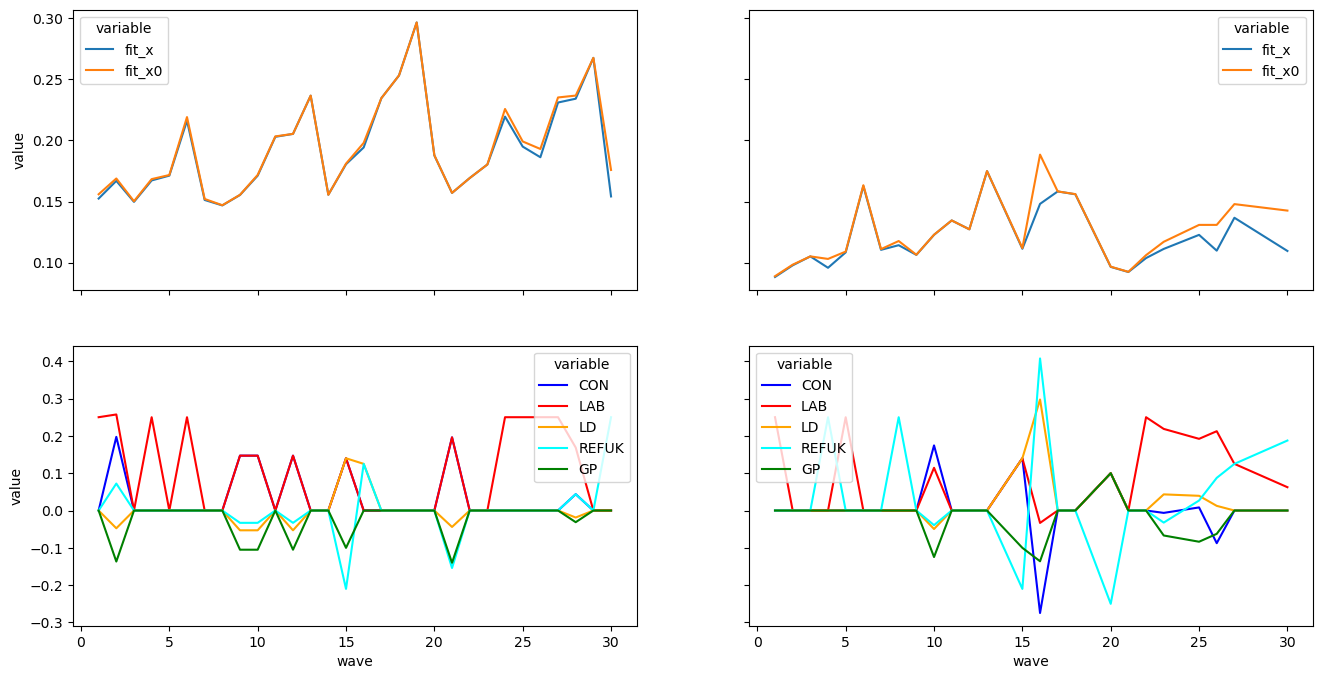

In [250]:
f, axs = plt.subplots(2,2,figsize=(16,8),sharey='row',sharex=True);
palette_dict = {"CON":'blue',"LAB":'red',"LD":'orange',"REFUK":'cyan',"SNP":"yellow",'PC':"olive",'GP':"green",}
sns.lineplot(data=store_df[store_df["like_or_ptv"]=="like"].melt(id_vars=["wave"],value_vars = ["fit_x","fit_x0",]),
             x="wave",y="value",hue="variable",ax= axs[0,0]);

sns.lineplot(data=store_df[store_df["like_or_ptv"]=="ptv"].melt(id_vars=["wave"],value_vars = ["fit_x","fit_x0",]),
             x="wave",y="value",hue="variable",ax=axs[0,1]);

temp = store_df[store_df["like_or_ptv"]=="like"].melt(id_vars=["wave"],value_vars = ["CON","LAB","LD","REFUK","GP"])
temp["value"] = temp["value"]/scale
sns.lineplot(data=temp,
             x="wave",y="value",hue="variable",ax=axs[1,0],palette=palette_dict);
temp = store_df[store_df["like_or_ptv"]=="ptv"].melt(id_vars=["wave"],value_vars = ["CON","LAB","LD","REFUK","GP"])
temp["value"] = temp["value"]/scale
sns.lineplot(data=temp,
             x="wave",y="value",hue="variable",ax=axs[1,1],palette=palette_dict);

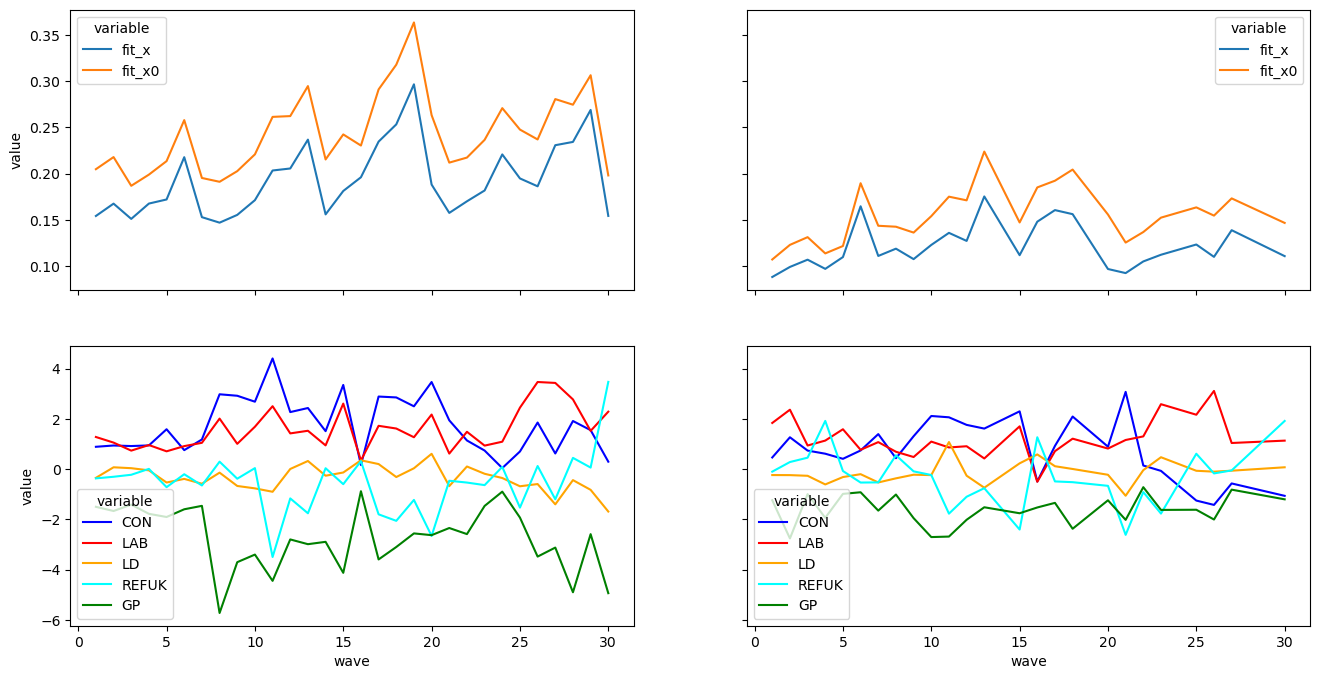

In [247]:
f, axs = plt.subplots(2,2,figsize=(16,8),sharey='row',sharex=True);
palette_dict = {"CON":'blue',"LAB":'red',"LD":'orange',"REFUK":'cyan',"SNP":"yellow",'PC':"olive",'GP':"green",}
sns.lineplot(data=store_df[store_df["like_or_ptv"]=="like"].melt(id_vars=["wave"],value_vars = ["fit_x","fit_x0",]),
             x="wave",y="value",hue="variable",ax= axs[0,0]);

sns.lineplot(data=store_df[store_df["like_or_ptv"]=="ptv"].melt(id_vars=["wave"],value_vars = ["fit_x","fit_x0",]),
             x="wave",y="value",hue="variable",ax=axs[0,1]);

temp = store_df[store_df["like_or_ptv"]=="like"].melt(id_vars=["wave"],value_vars = ["CON","LAB","LD","REFUK","GP"])
temp["value"] = temp["value"]/scale
sns.lineplot(data=temp,
             x="wave",y="value",hue="variable",ax=axs[1,0],palette=palette_dict);
temp = store_df[store_df["like_or_ptv"]=="ptv"].melt(id_vars=["wave"],value_vars = ["CON","LAB","LD","REFUK","GP"])
temp["value"] = temp["value"]/scale
sns.lineplot(data=temp,
             x="wave",y="value",hue="variable",ax=axs[1,1],palette=palette_dict);

In [246]:
store_df[store_df["like_or_ptv"]=="like"].melt(id_vars=["wave"],value_vars = ["CON","LAB","LD","REFUK","GP"])

,wave,variable,value
0,1,CON,0.000890
1,2,CON,0.000942
2,3,CON,0.000920
3,4,CON,0.000945
4,5,CON,0.001588
...,...,...,...
145,26,GP,-0.003480
146,27,GP,-0.003121
147,28,GP,-0.004900
148,29,GP,-0.002587


In [196]:
get_pred(res.x),get_pred(x0)

(0.15415364822642896, 0.19899834589229926)

In [158]:
res.x

array([ 2.19762560e-04,  9.48033920e-01, -9.32239232e-01,  9.92957312e-01,
       -1.00363251e+00])

In [129]:
party_replace_dict.keys()

dict_keys(['likeConW30', 'likeLabW30', 'likeLDW30', 'likeBrexitPartyW30', 'likeGrnW30'])

In [94]:

# pan_dataset_values


# # BES_Panel["ptvPCW16"][df["Economic: Left(0) <-> Right(10)"].notnull()].dropna()

# # df["ptvPCW16"].dropna()
# var_list
((df[x_lab][mask]-100)/20).describe()

count    20548.000000
mean         0.060188
std          3.073614
min         -5.000000
25%         -2.650000
50%          0.050000
75%          2.850000
max          5.000000
Name: Economic: Left(0) <-> Right(200){uniform}, dtype: float64

In [5]:
# search(BES_Panel,"al_scale")

wave_to_al_var = {1:"al_scaleW1_W5",2:"al_scaleW1_W5",3:"al_scaleW1_W5",4:"al_scaleW1_W5",5:"al_scaleW1_W5",
                    6:"al_scaleW6",7:"al_scaleW7_W9",8:"al_scaleW7_W9",9:"al_scaleW7_W9",
                    10:"al_scaleW10_W12",11:"al_scaleW10_W12",12:"al_scaleW10_W12",13:"al_scaleW13",
                    14:"al_scaleW14W15",15:"al_scaleW14W15",16:"al_scaleW16",
                    17:"al_scaleW17_W19",18:"al_scaleW17_W19",19:"al_scaleW17_W19",
                    20:"al_scaleW20",21:"al_scaleW21",22:"al_scaleW22",23:"al_scaleW23",24:"al_scaleW24",
                    25:"al_scaleW25W26",26:"al_scaleW25W26",27:"al_scaleW27W29",28:"al_scaleW27W29",29:"al_scaleW27W29",30:"al_scaleW30",
                    1987:"Social: Lib(0) <-> Auth(20)W1987",1992:"Social: Lib(0) <-> Auth(20)W1992",1997:"Social: Lib(0) <-> Auth(20)W1997",
                    2001:"Social: Lib(0) <-> Auth(20)W2001",2005:"Social: Lib(0) <-> Auth(20)W2005",2010:"Social: Lib(0) <-> Auth(20)W2010",
                    2015:"Social: Lib(0) <-> Auth(20)W2015",2017:"Social: Lib(0) <-> Auth(20)W2017",2019:"Social: Lib(0) <-> Auth(20)W2019",
                    2024:"Social: Lib(0) <-> Auth(20)W2024",
                   }

wave_to_lr_var = {1:"lr_scaleW1_W5",2:"lr_scaleW1_W5",3:"lr_scaleW1_W5",4:"lr_scaleW1_W5",5:"lr_scaleW1_W5",
                    6:"lr_scaleW6",7:"lr_scaleW7_W9",8:"lr_scaleW7_W9",9:"lr_scaleW7_W9",
                    10:"lr_scaleW10_W12",11:"lr_scaleW10_W12",12:"lr_scaleW10_W12",13:"lr_scaleW13",
                    14:"lr_scaleW14W15",15:"lr_scaleW14W15",16:"lr_scaleW16",
                    17:"lr_scaleW17_W19",18:"lr_scaleW17_W19",19:"lr_scaleW17_W19",
                    20:"lr_scaleW20",21:"lr_scaleW21",22:"lr_scaleW22",23:"lr_scaleW23",24:"lr_scaleW24",
                    25:"lr_scaleW25W26",26:"lr_scaleW25W26",27:"lr_scaleW27W29",28:"lr_scaleW27W29",29:"lr_scaleW27W29",30:"lr_scaleW30",
                    1987:"Economic: Left(0) <-> Right(20)W1987",1992:"Economic: Left(0) <-> Right(20)W1992",1997:"Economic: Left(0) <-> Right(20)W1997",
                    2001:"Economic: Left(0) <-> Right(20)W2001",2005:"Economic: Left(0) <-> Right(20)W2005",2010:"Economic: Left(0) <-> Right(20)W2010",
                    2015:"Economic: Left(0) <-> Right(20)W2015",2017:"Economic: Left(0) <-> Right(20)W2017",2019:"Economic: Left(0) <-> Right(20)W2019",
                    2024:"Economic: Left(0) <-> Right(20)W2024",
                   }

Friendly_description = BES_file_manifest[BES_file_manifest["Only_or_Combined"]=="Only"].set_index("Wave No")["Friendlier_Description"]
Friendly_description.loc[1987] = "BESf2f 1987 GE"
Friendly_description.loc[1992] = "BESf2f 1992 GE"
Friendly_description.loc[1997] = "BESf2f 1997 GE"
Friendly_description.loc[2001] = "BESf2f 2001 GE"
Friendly_description.loc[2005] = "BESf2f 2005 GE"
Friendly_description.loc[2010] = "BESf2f 2010 GE"
Friendly_description.loc[2015] = "BESf2f 2015 GE"
Friendly_description.loc[2017] = "BESf2f 2017 GE"
Friendly_description.loc[2019] = "BESf2f 2019 GE"
Friendly_description.loc[2024] = "BESf2f 2024 GE"

# wave_to_date

wave_to_date.loc[1987] = pd.to_datetime("11-06-1987")
wave_to_date.loc[1992] = pd.to_datetime("9-04-1992")
wave_to_date.loc[1997] = pd.to_datetime("1-05-1997")
wave_to_date.loc[2001] = pd.to_datetime("7-06-2001")
wave_to_date.loc[2005] = pd.to_datetime("5-05-2005")
wave_to_date.loc[2010] = pd.to_datetime("6-05-2010")
wave_to_date.loc[2015] = pd.to_datetime("7-05-2015")
wave_to_date.loc[2017] = pd.to_datetime("8-06-2017")
wave_to_date.loc[2019] = pd.to_datetime("12-12-2019")
wave_to_date.loc[2024] = pd.to_datetime("4-6-2024")#4 July 2024

In [6]:
all_bes_waves = list(range(1,31))+[1987,1992,1997,2001,2005,2010,2015,2017,2019,2024]

for wave in all_bes_waves:
    temp = pd.get_dummies(df["generalElectionVoteW"+str(wave)].replace(party_name_replace_dict)).astype('float')*10
    temp.columns = ["VI"+x+"W"+str(wave) for x in temp.columns]
    df[temp.columns] = temp        


In [7]:
q=11
all_bes_waves = list(range(1,31))+[1987,1992,1997,2001,2005,2010,2015,2017,2019,2024]
consolidate=False
wave_specific_values = True
parties = ["Con","Lab","LD","BrexitParty","UKIP","SNP","PC","Grn","TIG","BNP","DUP","OTH","Ref","SDP"]

# wave = 16
df_var = pd.DataFrame()

half_q = (q-1)/2
x_vec = np.linspace(-half_q, half_q,q)
y_vec = np.linspace(-half_q, half_q,q)
xdata, ydata = np.meshgrid(x_vec, y_vec)
xdata = xdata/half_q
ydata = ydata/half_q



for wave in all_bes_waves:
    for like_or_ptv in ["like","ptv","VI"]:
        var_list = [like_or_ptv+x+"W"+str(wave) for x in parties]
    
    
        for var in var_list:
            if var not in df.columns:
                continue
    
    
            
            if consolidate:
                
    
                mask = df["Economic: Left(0) <-> Right(10)"].notnull() & df["Social: Lib(0) <-> Auth(10)"].notnull() & df[var].notnull() 
                ct = pd.crosstab(df["Economic: Left(0) <-> Right(10)"],df["Social: Lib(0) <-> Auth(10)"],values = df[var],aggfunc=np.mean)
                zdata = ct.values
                # nans will break this, but probably reasonably so
                
            
                fit = Fit(model, x=xdata, y=ydata, z=zdata)
                fit_result = fit.execute()
                zfit = model(x=xdata, y=ydata, **fit_result.params).z

            elif wave_specific_values:

                granularity = 10
                y_lab = wave_to_lr_var[wave]
                #"Economic: Left(0) <-> Right(20)W"+str(wave)
                x_lab = wave_to_al_var[wave]
                #"Social: Lib(0) <-> Auth(20)W"+str(wave)
                
                mask = df[x_lab].notnull() & df[y_lab].notnull() & df[var].notnull()
                # store sample size?
                
                fit = Fit(model, x=((df[x_lab][mask]-granularity)/granularity).values, y=((df[y_lab][mask]-granularity)/granularity).values,
                          z=df[var][mask].values)
                fit_result = fit.execute()
                zfit = model(x=xdata, y=ydata, **fit_result.params).z     
    
            else:

                
                y_lab = "Economic: Left(0) <-> Right(200){uniform}"
                x_lab = "Social: Liberalism(0) <-> Conservatism(200){uniform}"
                granularity = 100
                
                mask = df[x_lab].notnull() & df[y_lab].notnull() & df[var].notnull()
                
                fit = Fit(model, x=((df[x_lab][mask]-granularity)/granularity).values, y=((df[y_lab][mask]-granularity)/granularity).values, z=df[var][mask].values)
                fit_result = fit.execute()
                zfit = model(x=xdata, y=ydata, **fit_result.params).z

            df[var+"_zfit"] = np.nan
            df.loc[mask,var+"_zfit"] =zfit
    
                
        
            df_var.loc[var,"fit_result"] = fit_result
            df_var.loc[var,"r_squared"] = fit_result.r_squared
            df_var.loc[var,"c1"] = fit_result.params["c1"]
            df_var.loc[var,"c2"] = fit_result.params["c2"]
            df_var.loc[var,"c3"] = fit_result.params["c3"]
            df_var.loc[var,"wave"] = wave

            df_var.loc[var,"type"] = like_or_ptv
            df_var.loc[var,"party"] = var.split(like_or_ptv)[1].split("W")[0]
    
            if consolidate:
                df_var.loc[var,"max_pos_x"] = ct.stack().idxmax()[0]
                df_var.loc[var,"max_pos_y"] = ct.stack().idxmax()[1]
                df_var.loc[var,"max_val"] = ct.stack().max()
                df_var.loc[var,"min_val"] = ct.stack().min()
            else:
                df_var.loc[var,"max_pos_x"] = pd.DataFrame(zfit).stack().idxmax()[0]
                df_var.loc[var,"max_pos_y"] = pd.DataFrame(zfit).stack().idxmax()[1]
                df_var.loc[var,"max_val"] = pd.DataFrame(zfit).stack().max()
                df_var.loc[var,"min_val"] = pd.DataFrame(zfit).stack().min()       
                
            df_var.loc[var,"N"]=(df["Economic: Left(0) <-> Right(10)"].notnull()&df["Social: Lib(0) <-> Auth(10)"].notnull()&df[var].notnull()).sum()
    
        
df_var["steepness"] = df_var.apply(lambda x: np.sqrt( (x["c1"]**2) + (x["c2"]**2) ), axis=1)
df_var["angle"] = df_var.apply(lambda x: np.arctan2(x["c1"], x["c2"]) * 180 / np.pi, axis=1)
# c2 = economic axis, c1 = soc axis
df_var["date_friendly"] = df_var["wave"].apply(lambda x: Friendly_description.loc[x])
df_var["date"] = df_var["wave"].apply(lambda x: wave_to_date.loc[x])

df_var[["c1","c2","c3","steepness","angle"]].to_pickle( "df_var.zip" , compression='zip' )

df_var.to_pickle( "df_var_all.zip" , compression='zip' )

ValueError: Must have equal len keys and value when setting with an ndarray

In [258]:
# max_wave = 30
# y = df_var[ (df_var["party"]=="Con") & (df_var["type"]=="like") ]["c3"].plot(label="Conservative Party",c='blue')
# x = BES_file_manifest[BES_file_manifest["Only_or_Combined"]=="Only"].set_index("Wave No")["Friendlier_Description"][::-1][0:max_wave]
# plt.xticks(range(0,max_wave),x,rotation=90);
# # plt.title("Competence Shocks For The Conservative Party");


In [ ]:
int_coeff_list = ["angle","c3","steepness","r_squared"]

palette_dict = {"Con":'blue',"Lab":'red',"LD":'orange',"UKIP":'purple',"SNP":"y",'PC':"olive",'Grn':"green",
                'BNP':'black',"TIG":'grey',"DUP":'magenta','BrexitParty':'cyan',
               'OTH':'grey',"Ref":'purple',"SDP":'magenta'}

for coeff in int_coeff_list:

    f, (ax1, ax2, ax3) = plt.subplots(1, 3, sharey=True,figsize=(16,6))
    sns.lineplot(data=df_var[df_var["type"]=="like"],y=coeff,x='date',hue='party',style='party',palette=palette_dict,ax=ax1,markers=True);
    ax1.set_title("like "+coeff);
    # ax1.xticks(rotation=90);
    ax1.tick_params(axis='x', labelrotation=90)
    ax1.set_xlabel("");
    ax1.set_ylabel(coeff);
    
    sns.lineplot(data=df_var[df_var["type"]=="ptv"],y=coeff,x='date',hue='party',style='party',palette=palette_dict,ax=ax2,legend=False,markers=True);
    ax2.set_title("ptv "+coeff);
    ax2.tick_params(axis='x', labelrotation=90)
    ax2.set_xlabel("");
    # sns.move_legend(ax1, 'upper center', 
    #                 bbox_to_anchor=(1.10, -0.10),
    #                 ncols=16,fontsize=12,title="");

    sns.lineplot(data=df_var[df_var["type"]=="VI"],y=coeff,x='date',hue='party',style='party',palette=palette_dict,ax=ax3,legend=False,markers=True);
    ax3.set_title("VI "+coeff);
    ax3.tick_params(axis='x', labelrotation=90)
    ax3.set_xlabel("");
    
    sns.move_legend(ax1, 'upper center', 
                    bbox_to_anchor=(1.10, -0.10),
                    ncols=16,fontsize=12,title="");    


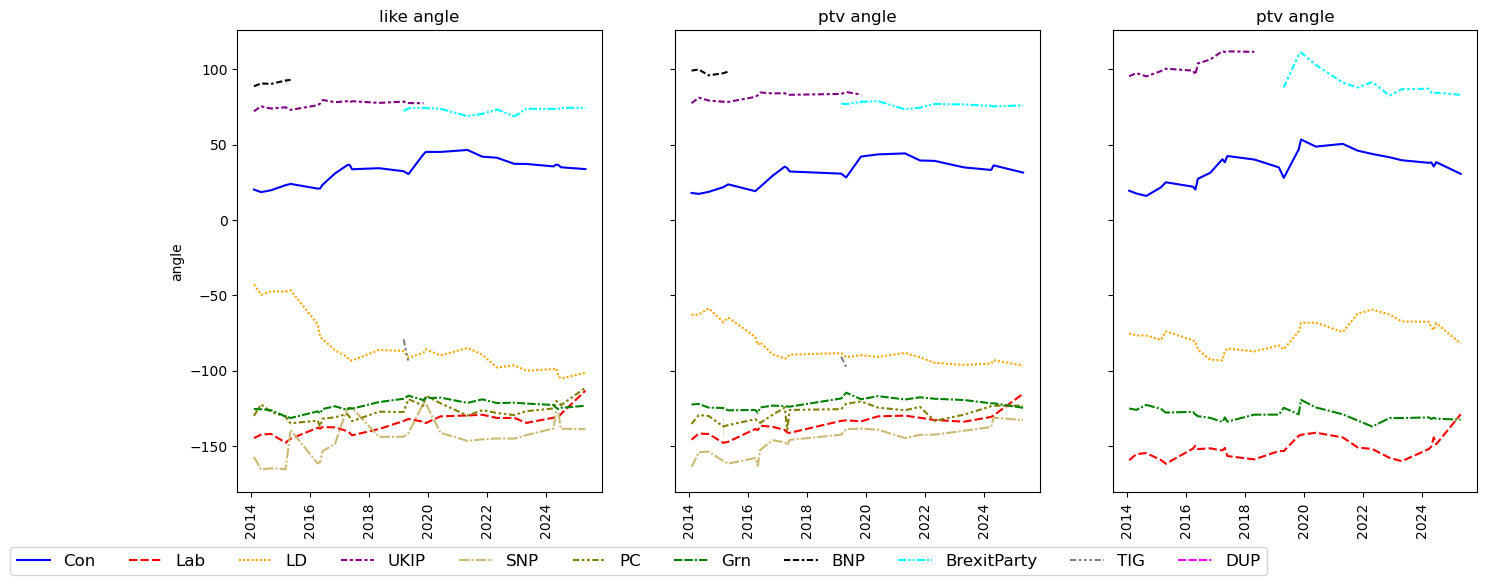

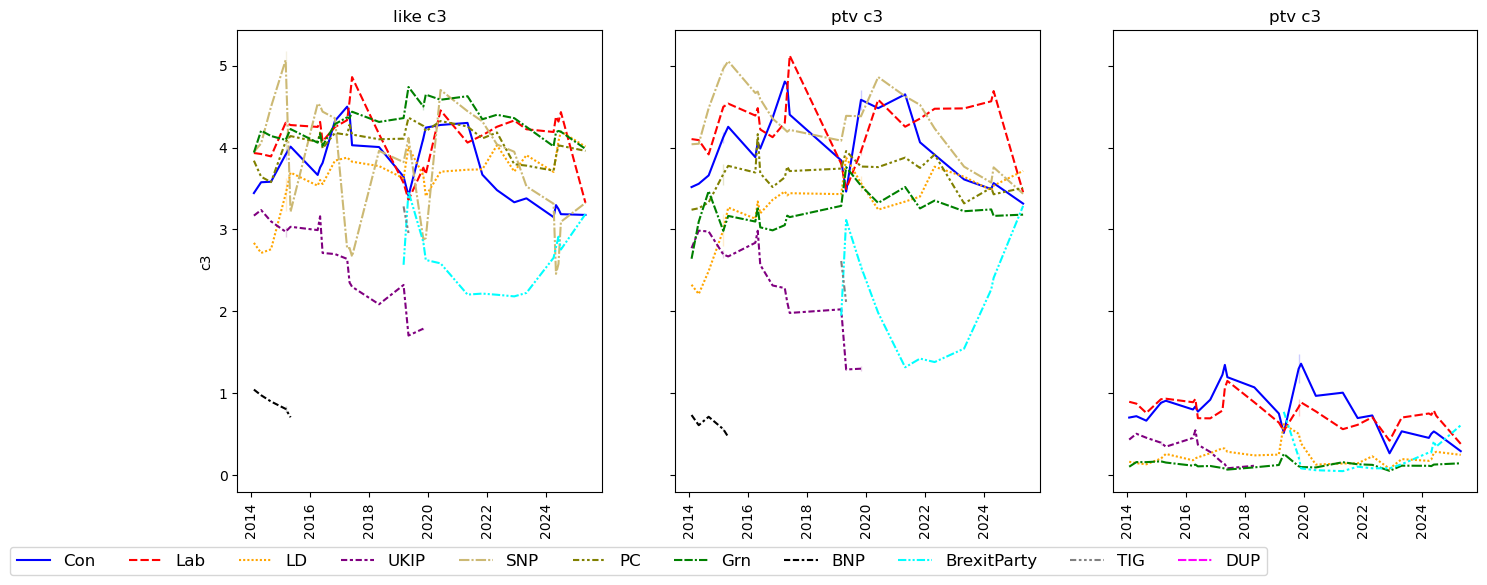

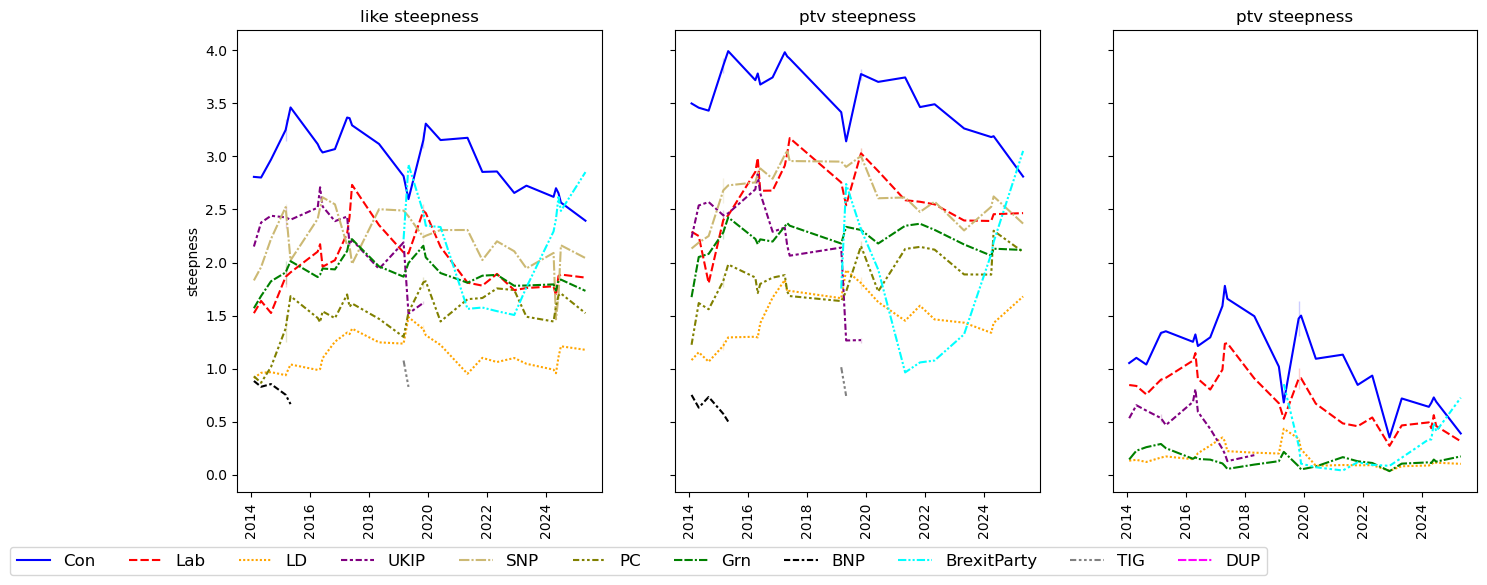

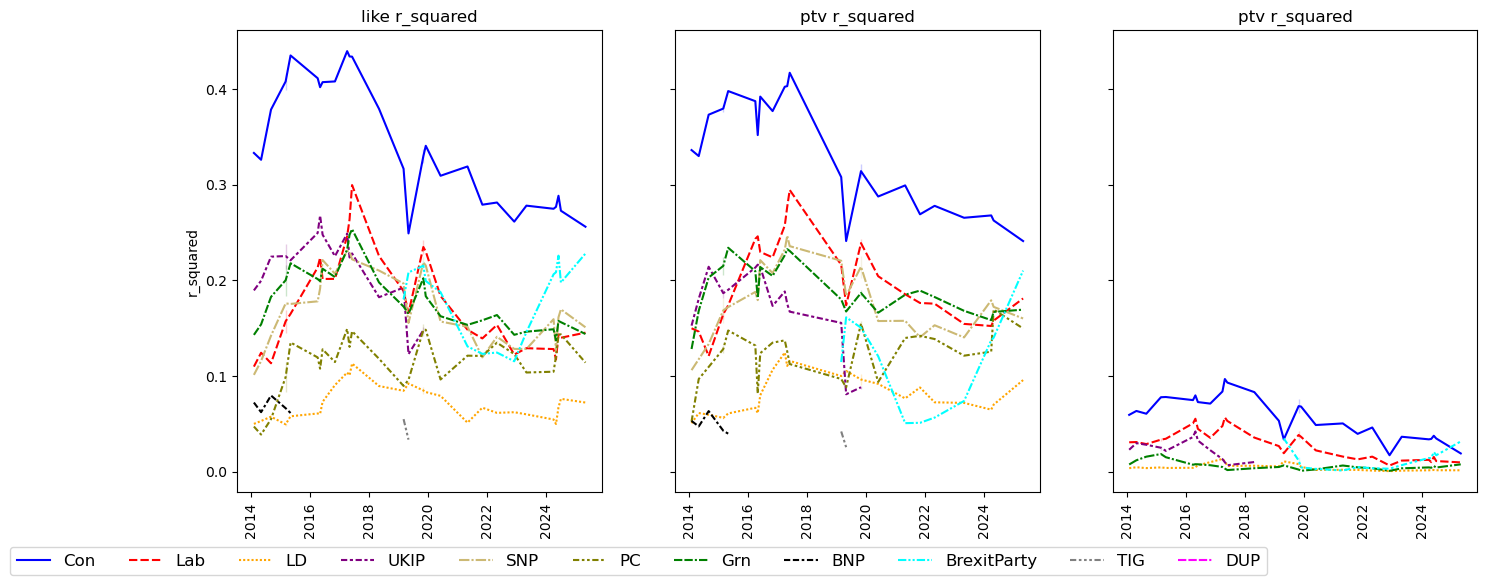

In [5]:
int_coeff_list = ["angle","c3","steepness","r_squared"]

palette_dict = {"Con":'blue',"Lab":'red',"LD":'orange',"UKIP":'purple',"SNP":"y",'PC':"olive",'Grn':"green",
                'BNP':'black',"TIG":'grey',"DUP":'magenta','BrexitParty':'cyan'}

for coeff in int_coeff_list:

    f, (ax1, ax2, ax3) = plt.subplots(1, 3, sharey=True,figsize=(16,6))
    sns.lineplot(data=df_var[df_var["type"]=="like"],y=coeff,x='date',hue='party',style='party',palette=palette_dict,ax=ax1);
    ax1.set_title("like "+coeff);
    # ax1.xticks(rotation=90);
    ax1.tick_params(axis='x', labelrotation=90)
    ax1.set_xlabel("");
    ax1.set_ylabel(coeff);
    
    sns.lineplot(data=df_var[df_var["type"]=="ptv"],y=coeff,x='date',hue='party',style='party',palette=palette_dict,ax=ax2,legend=False);
    ax2.set_title("ptv "+coeff);
    ax2.tick_params(axis='x', labelrotation=90)
    ax2.set_xlabel("");
    # sns.move_legend(ax1, 'upper center', 
    #                 bbox_to_anchor=(1.10, -0.10),
    #                 ncols=16,fontsize=12,title="");

    sns.lineplot(data=df_var[df_var["type"]=="VI"],y=coeff,x='date',hue='party',style='party',palette=palette_dict,ax=ax3,legend=False);
    ax3.set_title("VI "+coeff);
    ax3.tick_params(axis='x', labelrotation=90)
    ax3.set_xlabel("");
    
    sns.move_legend(ax1, 'upper center', 
                    bbox_to_anchor=(1.10, -0.10),
                    ncols=16,fontsize=12,title="");    


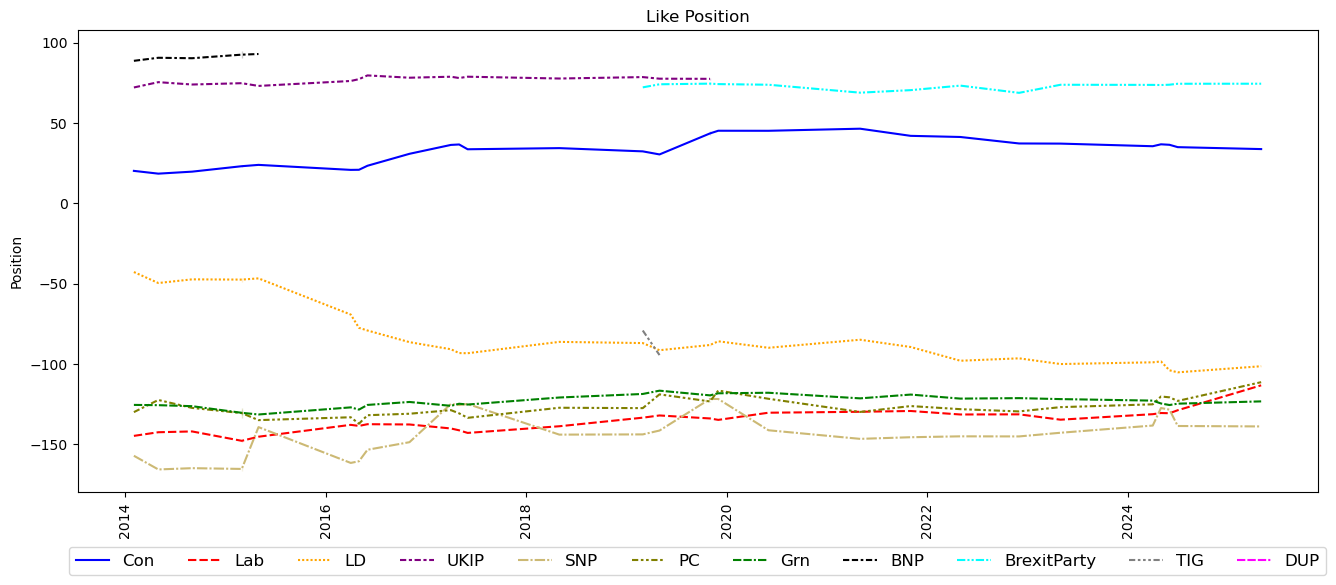

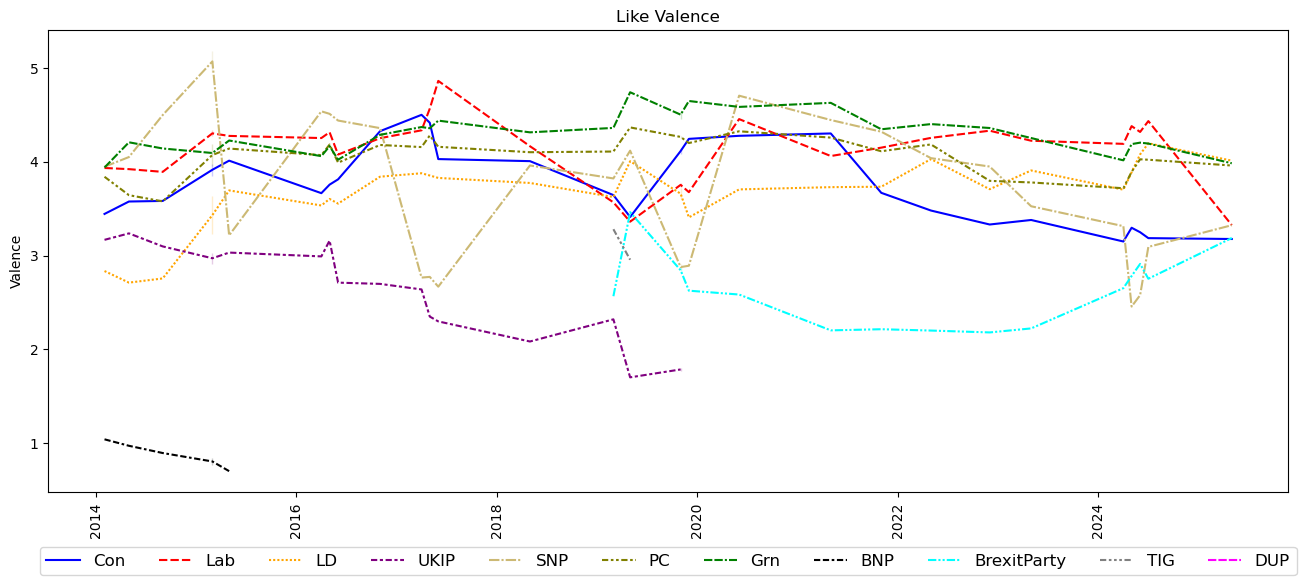

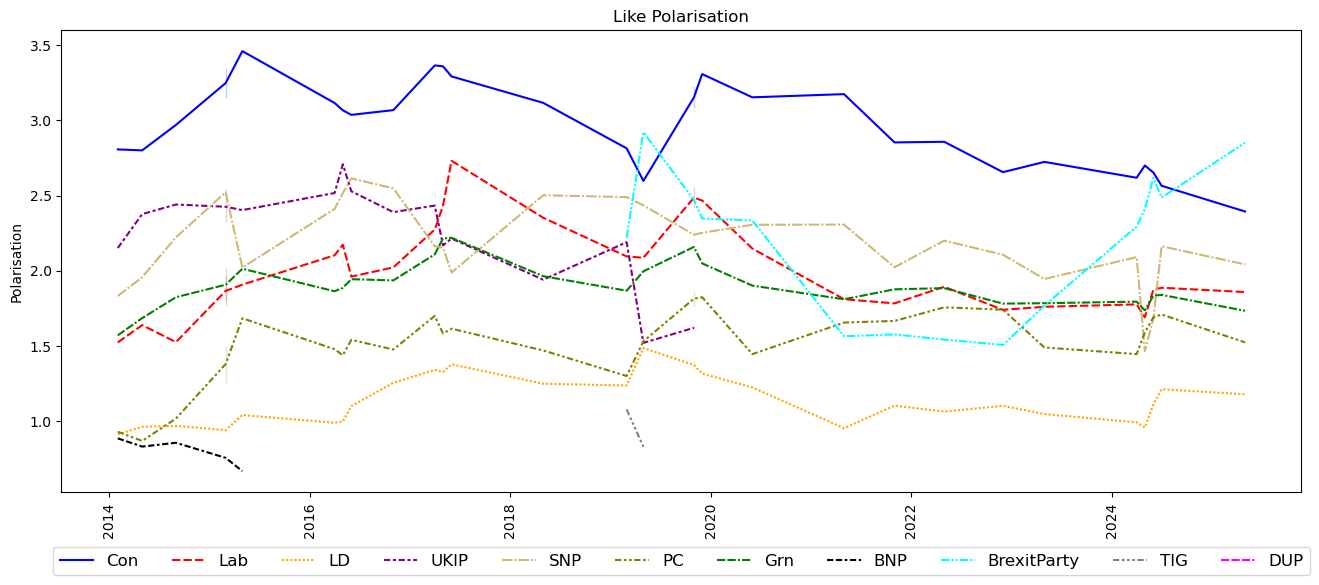

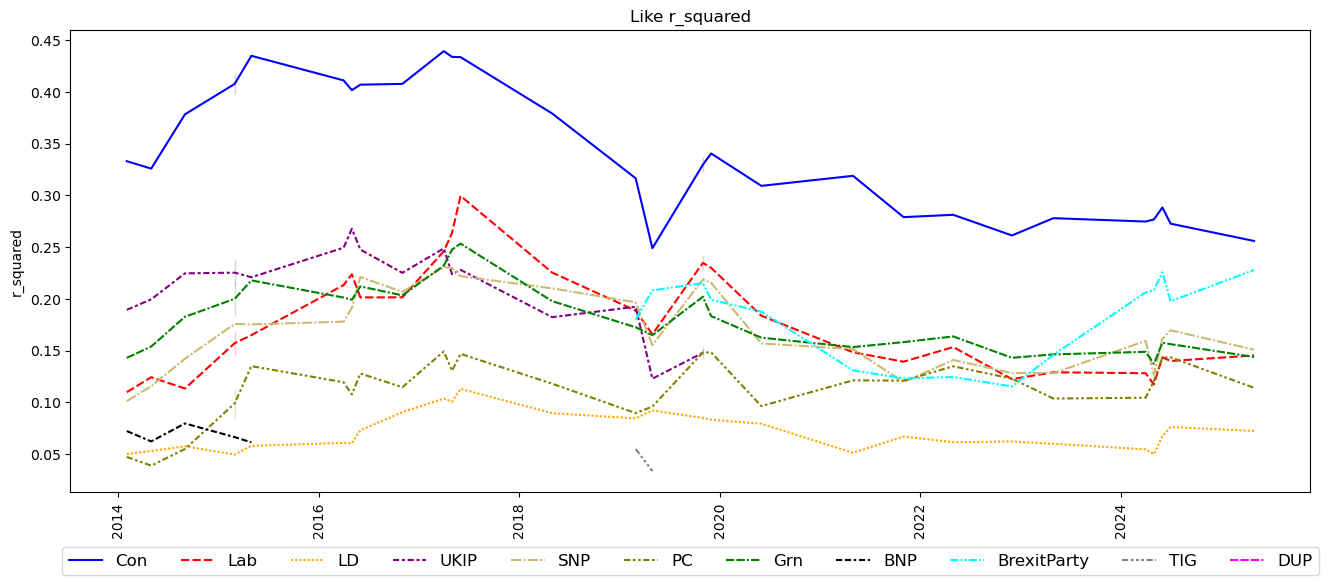

In [10]:
int_coeff_list = ["angle","c3","steepness","r_squared"]

palette_dict = {"Con":'blue',"Lab":'red',"LD":'orange',"UKIP":'purple',"SNP":"y",'PC':"olive",'Grn':"green",
                'BNP':'black',"TIG":'grey',"DUP":'magenta','BrexitParty':'cyan'}


coeff_replace_dict = {"angle":"Position","c3":"Valence","steepness":"Polarisation","r_squared":"r_squared"}
for coeff in int_coeff_list:

    f, (ax1) = plt.subplots(1, 1, sharey=True,figsize=(16,6))
    sns.lineplot(data=df_var[df_var["type"]=="like"],y=coeff,x='date',hue='party',style='party',palette=palette_dict,ax=ax1);
    ax1.set_title("Like "+coeff_replace_dict[coeff]);
    # ax1.xticks(rotation=90);
    ax1.tick_params(axis='x', labelrotation=90)
    ax1.set_xlabel("");
    ax1.set_ylabel(coeff_replace_dict[coeff]);
    
    # sns.lineplot(data=df_var[df_var["type"]=="ptv"],y=coeff,x='date',hue='party',style='party',palette=palette_dict,ax=ax2,legend=False);
    # ax2.set_title("ptv "+coeff);
    # ax2.tick_params(axis='x', labelrotation=90)
    # ax2.set_xlabel("");
    
    sns.move_legend(ax1, 'upper center', 
                    bbox_to_anchor=(0.5, -0.10),
                    ncols=16,fontsize=12,title="");


In [12]:
df_var[["c1","c2","c3","steepness","angle"]]


,c1,c2,c3,steepness,angle
likeConW1,0.969393,2.634426,3.443713,2.807120,20.202161
likeLabW1,-0.877118,-1.244865,3.933303,1.522835,-144.831891
likeLDW1,-0.619233,0.668839,2.835090,0.911480,-42.794547
likeUKIPW1,2.047210,0.659433,3.167806,2.150795,72.145578
likeSNPW1,-0.708974,-1.688648,3.946602,1.831442,-157.225042
...,...,...,...,...,...
VIConW30,0.198127,0.335249,0.289051,0.389418,30.582483
VILabW30,-0.245207,-0.198416,0.378215,0.315429,-128.979044
VILDW30,-0.102245,0.014143,0.244092,0.103218,-82.124551
VIBrexitPartyW30,0.720898,0.087484,0.605402,0.726187,83.080721


In [22]:
## plot like profiles
df

# lr_scale/al_scale data
# like/ptv/VI

,lr_scaleW1_W5,al_scaleW1_W5,lr_scaleW6,al_scaleW6,lr_scaleW7_W9,al_scaleW7_W9,lr_scaleW10_W12,al_scaleW10_W12,lr_scaleW13,al_scaleW13,...,VIConW2019,VIDKW2019,VIDNVW2019,VIGrnW2019,VILDW2019,VILabW2019,VIOTHW2019,VIPCW2019,VISNPW2019,VIUKIPW2019
1,1.0,16.0,0.0,17.0,1.0,16.0,2.0,16.0,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,15.0,12.0,14.0,10.0,9.0,12.0,NaN,9.0,9.0,9.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,7.0,NaN,4.0,14.0,NaN,15.0,5.0,15.0,5.0,14.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,7.0,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,11.0,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024|3084,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2024|3085,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2024|3086,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2024|3087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [19]:
df_var

,fit_result,r_squared,c1,c2,c3,wave,type,party,max_pos_x,max_pos_y,max_val,min_val,N,steepness,angle,date_friendly,date
likeConW1,\nParameter Value Standard Deviation\nc...,0.365356,1.792227,4.115120,4.622116,1.0,like,Con,10.0,10.0,10.529462,-1.285231,14636.0,4.488461,23.534208,2014: Spring,2014-02-01
likeLabW1,\nParameter Value Standard Deviation\nc...,0.113288,-1.310991,-1.950483,3.508788,1.0,like,Lab,0.0,0.0,6.770262,0.247315,14634.0,2.350123,-146.093507,2014: Spring,2014-02-01
likeLDW1,\nParameter Value Standard Deviation\nc...,0.048473,-0.801791,0.998413,3.455883,1.0,like,LD,10.0,0.0,5.256087,1.655679,14584.0,1.280507,-38.766724,2014: Spring,2014-02-01
likeUKIPW1,\nParameter Value Standard Deviation\nc...,0.200339,3.107420,0.760030,2.598346,1.0,like,UKIP,10.0,10.0,6.465797,-1.269105,14137.0,3.199017,76.256104,2014: Spring,2014-02-01
likeSNPW1,\nParameter Value Standard Deviation\nc...,0.108886,-1.146736,-2.681207,3.173406,1.0,like,SNP,0.0,0.0,7.001349,-0.654537,2819.0,2.916141,-156.843904,2014: Spring,2014-02-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
VIUKIPW2019,\nParameter Value Standard Deviation\nc...,0.000232,0.007530,0.001454,0.003898,2019.0,VI,UKIP,10.0,10.0,0.012882,-0.005086,96988.0,0.007670,79.074204,BESf2f 2019 GE,2019-12-12
VISNPW2019,\nParameter Value Standard Deviation\nc...,0.016635,-0.280917,-0.458552,0.252508,2019.0,VI,SNP,0.0,0.0,0.991977,-0.486960,96988.0,0.537758,-148.507641,BESf2f 2019 GE,2019-12-12
VIPCW2019,\nParameter Value Standard Deviation\nc...,0.001270,-0.014420,-0.055873,0.028618,2019.0,VI,PC,0.0,0.0,0.098911,-0.041675,96988.0,0.057704,-165.528400,BESf2f 2019 GE,2019-12-12
VIGrnW2019,\nParameter Value Standard Deviation\nc...,0.011518,-0.310537,-0.207265,0.257284,2019.0,VI,Grn,0.0,0.0,0.775085,-0.260518,96988.0,0.373352,-123.720790,BESf2f 2019 GE,2019-12-12


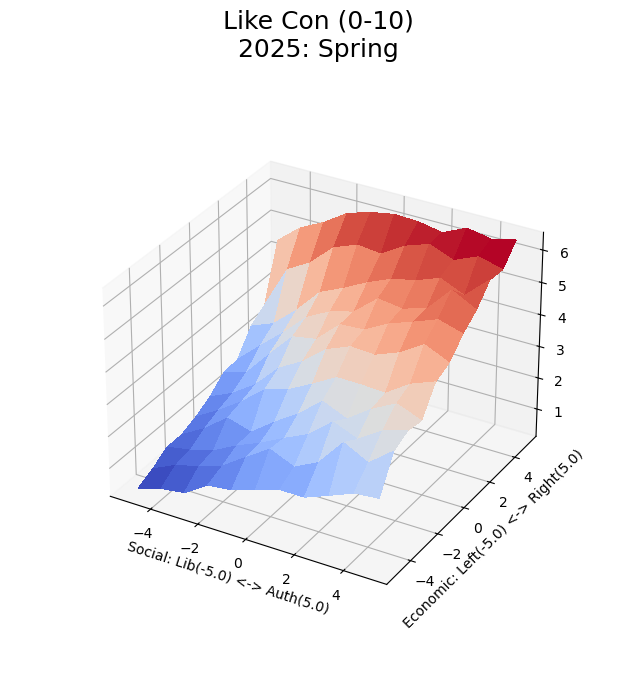

In [22]:
from matplotlib import cm

q=11
half_q = (q-1)/2
wave = 30
party = "Con"
like_or_ptv = "like"

y_lab = wave_to_lr_var[wave]
x_lab = wave_to_al_var[wave]

x_vec = np.linspace(-half_q, half_q,q)
y_vec = np.linspace(-half_q, half_q,q)
xdata, ydata = np.meshgrid(x_vec, y_vec)
zdata = pd.crosstab(pd.qcut(df[y_lab],q=q).cat.codes.replace(-1,np.nan)-half_q,
                    pd.qcut(df[x_lab],q=q).cat.codes.replace(-1,np.nan)-half_q,
                    values = df[like_or_ptv+party+"W"+str(wave)],aggfunc=np.mean).values






fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(projection='3d')


# Plot the surface.
surf = ax.plot_surface(xdata, ydata, zdata, cmap=cm.coolwarm,
                       linewidth=0, antialiased=False,)
# surf = ax.plot_surface(xdata, ydata, zdata, cmap=cm.coolwarm,
#                        linewidth=0, antialiased=False,)
ax.set(ylabel=("Economic: Left(-"+str(half_q)+") <-> Right("+str(half_q)+")"),
                       xlabel=("Social: Lib(-"+str(half_q)+") <-> Auth("+str(half_q)+")"),
      );
ax.set_title("Like "+party+" (0-10)\n"+Friendly_description[wave], fontsize=18)
ax.set_box_aspect(aspect=None, zoom=0.8)


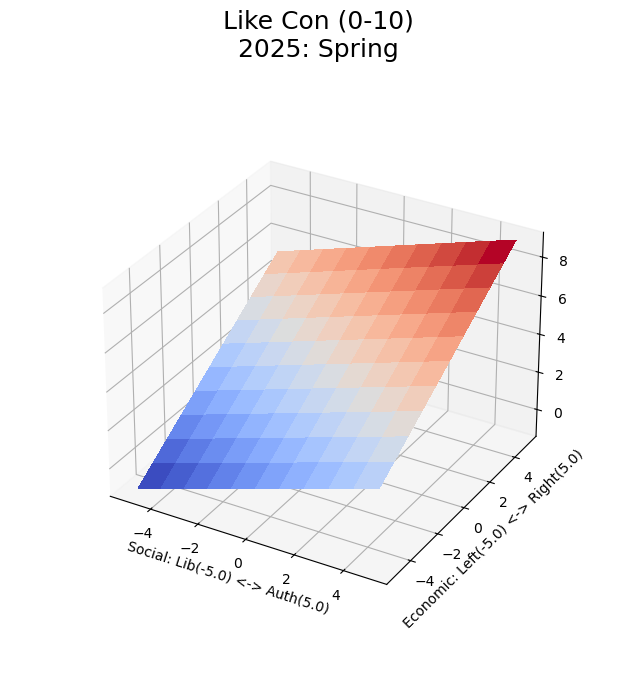

In [24]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(projection='3d')


# Plot the surface.
# surf = ax.plot_surface(xdata, ydata, zdata, cmap=cm.coolwarm,
#                        linewidth=0, antialiased=False,)

fit_result = df_var.loc[like_or_ptv+party+"W"+str(wave),"fit_result"]
zfit = model(x=xdata/half_q, y=ydata/half_q, **fit_result.params).z

surf = ax.plot_surface(xdata, ydata, zfit, cmap=cm.coolwarm,
                       linewidth=0, antialiased=False,)
ax.set(ylabel=("Economic: Left(-"+str(half_q)+") <-> Right("+str(half_q)+")"),
                       xlabel=("Social: Lib(-"+str(half_q)+") <-> Auth("+str(half_q)+")"),
      );
ax.set_title("Like "+party+" (0-10)\n"+Friendly_description[wave], fontsize=18)
ax.set_box_aspect(aspect=None, zoom=0.8)

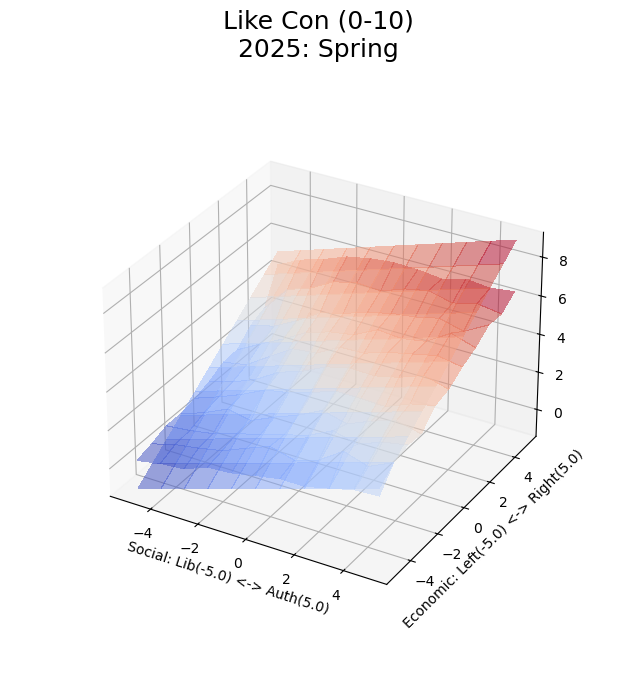

In [26]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(projection='3d')


# Plot the surface.
# surf = ax.plot_surface(xdata, ydata, zdata, cmap=cm.coolwarm,
#                        linewidth=0, antialiased=False,)

fit_result = df_var.loc[like_or_ptv+party+"W"+str(wave),"fit_result"]
zfit = model(x=xdata/half_q, y=ydata/half_q, **fit_result.params).z

surf = ax.plot_surface(xdata, ydata, zfit, cmap=cm.coolwarm,
                       linewidth=0, antialiased=False,alpha=.5)

surf = ax.plot_surface(xdata, ydata, zdata, cmap=cm.coolwarm,
                       linewidth=0, antialiased=False,alpha=.5)


ax.set(ylabel=("Economic: Left(-"+str(half_q)+") <-> Right("+str(half_q)+")"),
                       xlabel=("Social: Lib(-"+str(half_q)+") <-> Auth("+str(half_q)+")"),
      );
ax.set_title("Like "+party+" (0-10)\n"+Friendly_description[wave], fontsize=18)
ax.set_box_aspect(aspect=None, zoom=0.8)

best n_components by PCA CV = 2
best n_components by FactorAnalysis CV = 2
best n_components by PCA MLE = 2


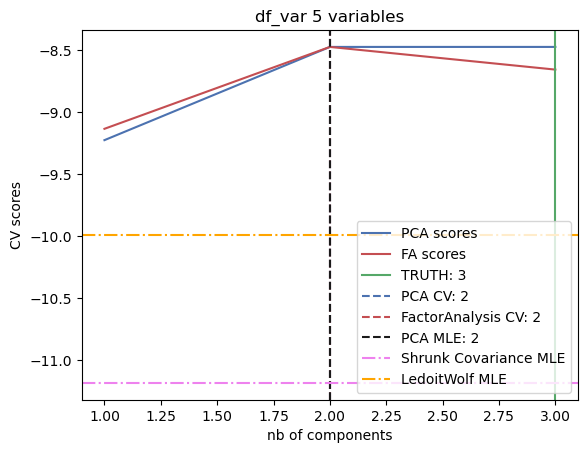

In [28]:
import matplotlib.pyplot as plt

from sklearn.covariance import LedoitWolf, ShrunkCovariance
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.model_selection import GridSearchCV, cross_val_score

n_features = 3
rank  = 3

n_components = np.arange(1, n_features+1)  # options for n_components


def compute_scores(X):
    pca = PCA(svd_solver="full")
    fa = FactorAnalysis()

    pca_scores, fa_scores = [], []
    for n in n_components:
        pca.n_components = n
        fa.n_components = n
        pca_scores.append(np.mean(cross_val_score(pca, X)))
        fa_scores.append(np.mean(cross_val_score(fa, X)))

    return pca_scores, fa_scores


def shrunk_cov_score(X):
    shrinkages = np.logspace(-2, 0, 30)
    cv = GridSearchCV(ShrunkCovariance(), {"shrinkage": shrinkages})
    return np.mean(cross_val_score(cv.fit(X).best_estimator_, X))


def lw_score(X):
    return np.mean(cross_val_score(LedoitWolf(), X))


for X, title in [(df_var[["c3","steepness","angle"]].values, "df_var 5 variables"),]:
    pca_scores, fa_scores = compute_scores(X)
    n_components_pca = n_components[np.argmax(pca_scores)]
    n_components_fa = n_components[np.argmax(fa_scores)]

    pca = PCA(svd_solver="full", n_components="mle")
    pca.fit(X)
    n_components_pca_mle = pca.n_components_

    print("best n_components by PCA CV = %d" % n_components_pca)
    print("best n_components by FactorAnalysis CV = %d" % n_components_fa)
    print("best n_components by PCA MLE = %d" % n_components_pca_mle)

    plt.figure()
    plt.plot(n_components, pca_scores, "b", label="PCA scores")
    plt.plot(n_components, fa_scores, "r", label="FA scores")
    plt.axvline(rank, color="g", label="TRUTH: %d" % rank, linestyle="-")
    plt.axvline(
        n_components_pca,
        color="b",
        label="PCA CV: %d" % n_components_pca,
        linestyle="--",
    )
    plt.axvline(
        n_components_fa,
        color="r",
        label="FactorAnalysis CV: %d" % n_components_fa,
        linestyle="--",
    )
    plt.axvline(
        n_components_pca_mle,
        color="k",
        label="PCA MLE: %d" % n_components_pca_mle,
        linestyle="--",
    )

    # compare with other covariance estimators
    plt.axhline(
        shrunk_cov_score(X),
        color="violet",
        label="Shrunk Covariance MLE",
        linestyle="-.",
    )
    plt.axhline(
        lw_score(X),
        color="orange",
        label="LedoitWolf MLE" % n_components_pca_mle,
        linestyle="-.",
    )

    plt.xlabel("nb of components")
    plt.ylabel("CV scores")
    plt.legend(loc="lower right")
    plt.title(title)

plt.show()

In [41]:
from sklearn.preprocessing import StandardScaler

X = df_var[["c3","steepness","angle"]]
# X = pd.DataFrame(StandardScaler().fit_transform(X),columns=X.columns)
fa = FactorAnalysis(n_components=2)
fa.fit(X.values)
pd.DataFrame( fa.components_ )

,0,1,2
0,-0.524594,0.044420,90.728423
1,1.380776,0.887689,0.022393


,0,1,2
0,0.935119,0.900291,-0.201568
1,-0.176959,0.281158,0.809405


In [45]:
from sklearn.preprocessing import StandardScaler

X = df_var[["c3","steepness","angle"]]
# X = pd.DataFrame(StandardScaler().fit_transform(X),columns=X.columns)
pca = PCA(n_components=2)
pca.fit(X.values)
pd.DataFrame( pca.components_ )

,0,1,2
0,-0.005779,0.000491,0.999983
1,0.856469,0.516178,0.004696


In [47]:
df_var[["c1","c2","c3","steepness","angle"]].corr()

,c1,c2,c3,steepness,angle
c1,1.000000,0.760333,-0.321091,0.120423,0.834998
c2,0.760333,1.000000,-0.209133,0.132963,0.693330
c3,-0.321091,-0.209133,1.000000,0.792313,-0.332024
steepness,0.120423,0.132963,0.792313,1.000000,0.046426
angle,0.834998,0.693330,-0.332024,0.046426,1.000000


In [52]:
df_var[["c1","c2","c3","steepness","angle"]][df_var["r_squared"]>df_var["r_squared"].mean()].corr()

,c1,c2,c3,steepness,angle
c1,1.000000,0.809527,-0.440059,0.469393,0.968434
c2,0.809527,1.000000,-0.248951,0.601077,0.825842
c3,-0.440059,-0.248951,1.000000,0.221998,-0.566025
steepness,0.469393,0.601077,0.221998,1.000000,0.409707
angle,0.968434,0.825842,-0.566025,0.409707,1.000000


In [57]:
from sklearn.preprocessing import StandardScaler

X = df_var[["c3","steepness","angle"]][df_var["r_squared"]>df_var["r_squared"].mean()]
X = pd.DataFrame(StandardScaler().fit_transform(X),columns=X.columns)
pca = PCA(n_components=2)
pca.fit(X.values)
pd.DataFrame( pca.components_ )

,0,1,2
0,-0.594422,0.289317,0.750305
1,0.552764,0.824663,0.119932


In [96]:
search(BES_Panel,"warm")

warmDenmarkW7        7682
warmFranceW7         7682
warmPolandW7         7682
warmRomaniaW7        7682
warmGreeceW7         7682
warmSpainW7          7682
warmUKW7             7682
warmWhiteW11        30953
warmAsianW11        30953
warmBlackW11        30953
warmEasternW11       7689
warmSyriansW11       7689
warmIndianW11        7689
warmWCW11            7689
warmMCW11            7689
warmBenefitsW11      7689
warmPoorW11          7689
warmRichW11          7689
warmMuslimW11        7689
warmChristianW11     7689
warmJewishW11        7689
warmAtheistW11       7689
warmMuslimW15        6982
warmChristianW15     6982
warmJewishW15        6982
warmAtheistW15       6982
warmMuslimW26       30064
warmChristianW26    30064
warmJewishW26       30064
warmAtheistW26      30064
dtype: int64

<Axes: >

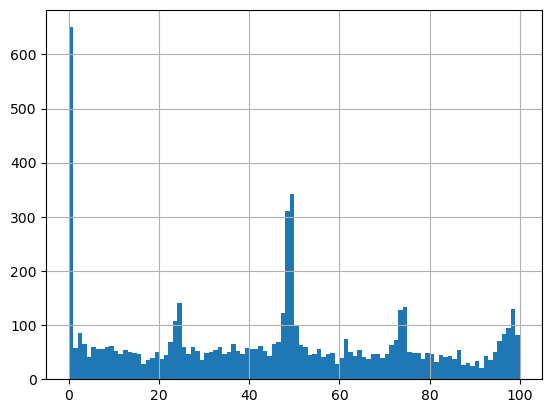

In [99]:
BES_Panel["warmSyriansW11"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan).hist(bins=100)

Text(0.5, 1.0, 'Please rate your feelings towards people from <Romania>,\nwith one hundred meaning a very warm, favourable feeling,\nzero meaning a very cold, unfavourable feeling, and fifty\nmeaning not particularly warm or cold.')

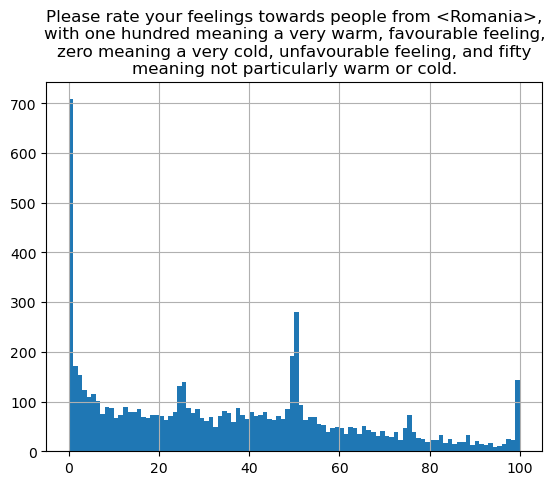

In [107]:
BES_Panel["warmRomaniaW7"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan).hist(bins=100);
title_string = "Please rate your feelings towards people from <Romania>, with one hundred meaning a very warm, favourable feeling, zero meaning a very cold, unfavourable feeling, and fifty meaning not particularly warm or cold."
import textwrap
plt.title(textwrap.fill(title_string, 60))

In [30]:
friendly_date = BES_file_manifest[BES_file_manifest["Only_or_Combined"]=="Only"].set_index("Wave No")["Friendlier_Description"][::-1]

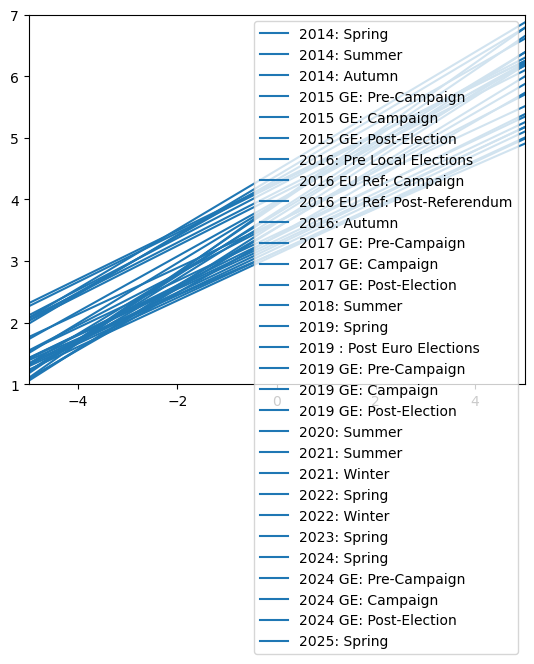

In [32]:
fig = plt.figure()
ax=plt.gca()
ax.set_xlim(-5,5);
ax.set_ylim(1,7);

slope      = df_var[ (df_var["party"]=="Con") & (df_var["type"]=="like") ]["c2"]
intercepts = df_var[ (df_var["party"]=="Con") & (df_var["type"]=="like") ]["c3"]

for x in slope.index:
    ax.axline(xy1=(0,intercepts.loc[x]),slope=slope.loc[x],label=friendly_date[int(x.split("likeConW")[1])]);
plt.legend()

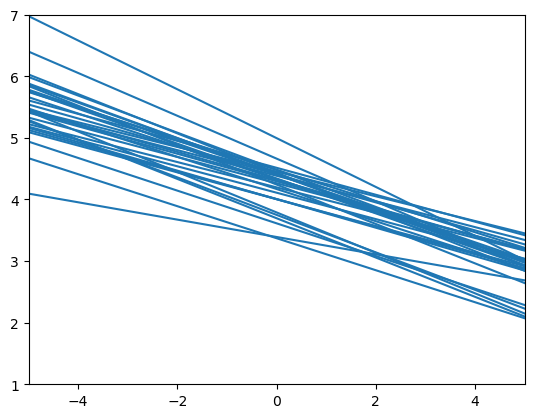

In [33]:
fig = plt.figure()
ax=plt.gca()
ax.set_xlim(-5,5);
ax.set_ylim(1,7);

slope      = df_var[ (df_var["party"]=="Lab") & (df_var["type"]=="like") ]["c2"]
intercepts = df_var[ (df_var["party"]=="Lab") & (df_var["type"]=="like") ]["c3"]

for x in slope.index:
    ax.axline(xy1=(0,intercepts.loc[x]),slope=slope.loc[x],label=friendly_date[int(x.split("likeLabW")[1])]);
# plt.legend()

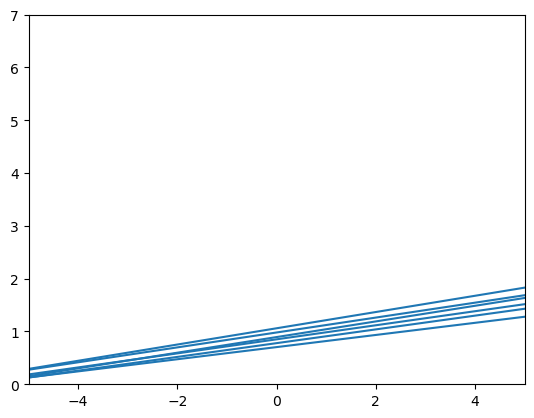

In [302]:
fig = plt.figure()
ax=plt.gca()
ax.set_xlim(-5,5);
ax.set_ylim(0,7);

slope      = df_var[ (df_var["party"]=="BNP") & (df_var["type"]=="like") ]["c1"]
intercepts = df_var[ (df_var["party"]=="BNP") & (df_var["type"]=="like") ]["c3"]

for x in slope.index:
    ax.axline(xy1=(0,intercepts.loc[x]),slope=slope.loc[x],label=friendly_date[int(x.split("likeBNPW")[1])]);
# plt.legend()

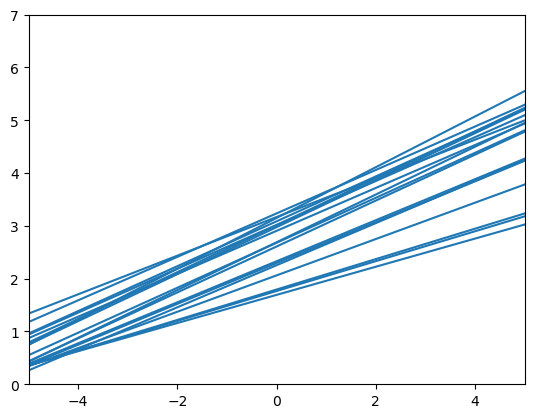

In [301]:
fig = plt.figure()
ax=plt.gca()
ax.set_xlim(-5,5);
ax.set_ylim(0,7);

slope      = df_var[ (df_var["party"]=="UKIP") & (df_var["type"]=="like") ]["c1"]
intercepts = df_var[ (df_var["party"]=="UKIP") & (df_var["type"]=="like") ]["c3"]

for x in slope.index:
    ax.axline(xy1=(0,intercepts.loc[x]),slope=slope.loc[x],label=friendly_date[int(x.split("likeUKIPW")[1])]);
# plt.legend()

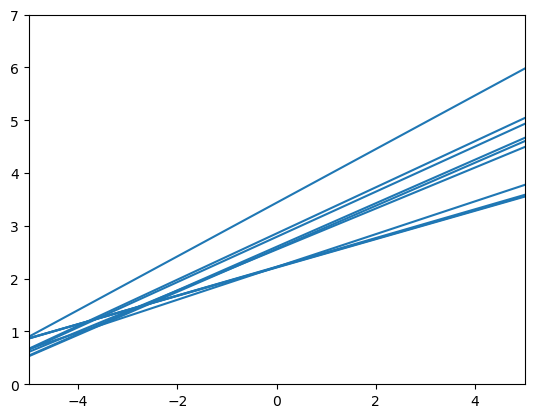

In [300]:
fig = plt.figure()
ax=plt.gca()
ax.set_xlim(-5,5);
ax.set_ylim(0,7);

slope      = df_var[ (df_var["party"]=="BrexitParty") & (df_var["type"]=="like") ]["c1"]
intercepts = df_var[ (df_var["party"]=="BrexitParty") & (df_var["type"]=="like") ]["c3"]

for x in slope.index:
    ax.axline(xy1=(0,intercepts.loc[x]),slope=slope.loc[x],label=friendly_date[int(x.split("likeBrexitPartyW")[1])]);
# plt.legend()

In [273]:
df_var[ (df_var["party"]=="Con") & (df_var["type"]=="like") ]["c2"]

likeConW1     0.463024
likeConW2     0.465916
likeConW3     0.491316
likeConW4     0.517128
likeConW5     0.547106
likeConW6     0.567831
likeConW7     0.512337
likeConW8     0.501631
likeConW9     0.487203
likeConW10    0.457395
likeConW11    0.479472
likeConW12    0.480438
likeConW13    0.488102
likeConW14    0.448542
likeConW15    0.415449
likeConW16    0.396916
likeConW17    0.406733
likeConW18    0.410076
likeConW19    0.418170
likeConW20    0.397907
likeConW21    0.393187
likeConW22    0.374604
likeConW23    0.380101
likeConW24    0.374912
likeConW25    0.382462
Name: c2, dtype: float64

In [107]:
# df_var[ (df_var["party"]=="UKIP") & (df_var["type"]=="like") ]

In [108]:
# df_var.sort_values(by='r_squared').dropna()[50:].head(50)

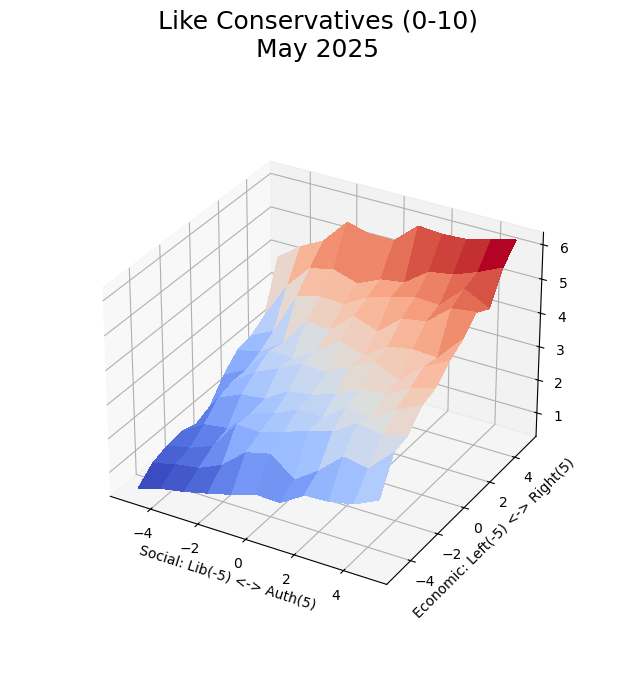

In [35]:
from matplotlib import cm
# from matplotlib.ticker import LinearLocator

half_q = (q-1)/2
x_vec = np.linspace(-half_q, half_q,q)
y_vec = np.linspace(-half_q, half_q,q)
xdata, ydata = np.meshgrid(x_vec, y_vec)
zdata = pd.crosstab(df["Economic: Left(0) <-> Right(10)"],df["Social: Lib(0) <-> Auth(10)"],values = df["likeConW30"],aggfunc=np.mean).values


# fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(projection='3d')

# # Make data.
# X = np.arange(-5, 5, 0.25)
# Y = np.arange(-5, 5, 0.25)
# X, Y = np.meshgrid(X, Y)
# R = np.sqrt(X**2 + Y**2)
# Z = np.sin(R)

# Plot the surface.
surf = ax.plot_surface(xdata, ydata, zdata, cmap=cm.coolwarm,
                       linewidth=0, antialiased=False,)
ax.set(ylabel=("Economic: Left(-5) <-> Right(5)"),
                       xlabel=("Social: Lib(-5) <-> Auth(5)"),
                       # zlabel=("Like Conservatives (0-10)")
      );
ax.set_title('Like Conservatives (0-10)\nMay 2025', fontsize=18)
ax.set_box_aspect(aspect=None, zoom=0.8)
# plt.xlabel();
# plt.ylabel();
# plt.zlabel("Social: Lib(-5) <-> Auth(5)");

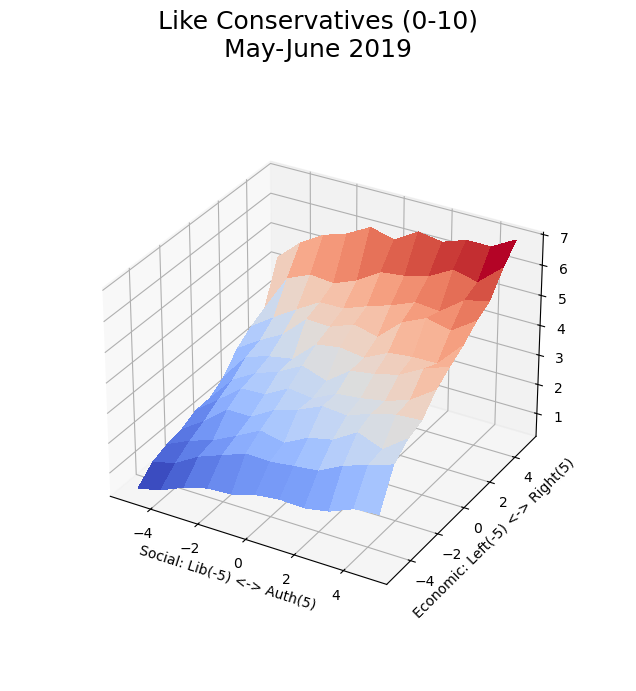

In [34]:
from matplotlib import cm
# from matplotlib.ticker import LinearLocator

half_q = (q-1)/2
x_vec = np.linspace(-half_q, half_q,q)
y_vec = np.linspace(-half_q, half_q,q)
xdata, ydata = np.meshgrid(x_vec, y_vec)
zdata = pd.crosstab(df["Economic: Left(0) <-> Right(10)"],df["Social: Lib(0) <-> Auth(10)"],values = df["likeConW16"],aggfunc=np.mean).values


# fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(projection='3d')

# # Make data.
# X = np.arange(-5, 5, 0.25)
# Y = np.arange(-5, 5, 0.25)
# X, Y = np.meshgrid(X, Y)
# R = np.sqrt(X**2 + Y**2)
# Z = np.sin(R)

# Plot the surface.
surf = ax.plot_surface(xdata, ydata, zdata, cmap=cm.coolwarm,
                       linewidth=0, antialiased=False,)
ax.set(ylabel=("Economic: Left(-5) <-> Right(5)"),
                       xlabel=("Social: Lib(-5) <-> Auth(5)"),
                       # zlabel=("Like Conservatives (0-10)")
      );
ax.set_title('Like Conservatives (0-10)\nMay-June 2019', fontsize=18)
ax.set_box_aspect(aspect=None, zoom=0.8)
# plt.xlabel();
# plt.ylabel();
# plt.zlabel("Social: Lib(-5) <-> Auth(5)");

In [109]:




# # Perform the fit
# fit = Fit(model, x=xdata, y=ydata, z=zdata)
# fit_result = fit.execute()
# zfit = model(x=xdata, y=ydata, **fit_result.params).z
# print(fit_result)

# fig, (ax1, ax2) = plt.subplots(1, 2)
# sns.heatmap(zdata, ax=ax1)
# sns.heatmap(zfit, ax=ax2)
# plt.show()

In [163]:
fry_var = ["Social: Liberalism(0) <-> Conservatism(200){uniform}","Economic: Left(0) <-> Right(200){uniform}"]

xdata = df["Economic: Left(0) <-> Right(10)"]
ydata = df["Social: Lib(0) <-> Auth(10)"]

# xdata = df[fry_var[0]]
# ydata = df[fry_var[1]]
zdata = df["likeBrexitPartyW16"]
mask = xdata.notnull()&ydata.notnull()&zdata.notnull()
xdata = xdata[mask].values
ydata = ydata[mask].values
zdata = zdata[mask].values


# Perform the fit
fit = Fit(model, x=xdata, y=ydata, z=zdata)
fit_result = fit.execute()
zfit = model(x=xdata, y=ydata, **fit_result.params).z
print(fit_result)


Parameter Value        Standard Deviation
c1        1.451655e-01 5.760736e-03
c2        5.090808e-01 5.771184e-03
c3        1.826338e-01 4.461157e-02
Status message         Optimization terminated successfully.
Number of iterations   5
Objective              <symfit.core.objectives.LeastSquares object at 0x000002139CC28340>
Minimizer              <symfit.core.minimizers.BFGS object at 0x000002139A8BD930>

Goodness of fit qualifiers:
chi_squared            387879.7644165366
objective_value        193939.8822082683
r_squared              0.205775525169425


[z(x, y; c1, c2) = c1*x**2 + c1*y**2 + c2*x*y]

Parameter Value        Standard Deviation
c1        9.997600e-01 1.180783e-03
c2        2.001121e+00 3.667262e-03
Status message         Optimization terminated successfully.
Number of iterations   4
Objective              <symfit.core.objectives.LeastSquares object at 0x00000213999CB4F0>
Minimizer              <symfit.core.minimizers.BFGS object at 0x0000021399997FD0>

Goodness of fit qualifiers:
chi_squared            25273.309393059342
objective_value        12636.654696529671
r_squared              0.9954763222485207


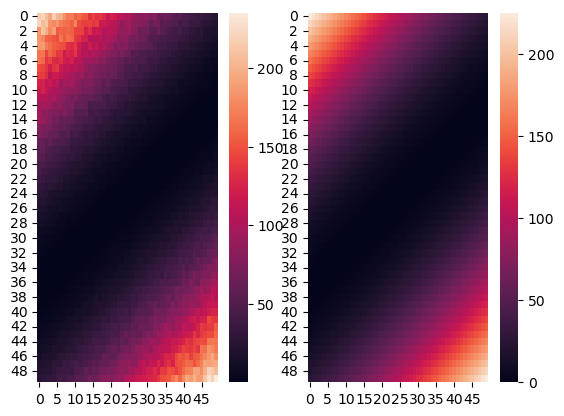

In [76]:
from symfit import Poly, variables, parameters, Model, Fit
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns

x, y, z = variables('x, y, z')
c1, c2 = parameters('c1, c2')
# Make a polynomial. Note the `as_expr` to make it symfit friendly.
model_dict = {
    z: Poly( {(2, 0): c1, (0, 2): c1, (1, 1): c2}, x ,y).as_expr()
}
model = Model(model_dict)
print(model)

# Generate example data
x_vec = np.linspace(-5, 5)
y_vec = np.linspace(-10, 10)
xdata, ydata = np.meshgrid(x_vec, y_vec)
zdata = model(x=xdata, y=ydata, c1=1.0, c2=2.0).z
zdata = np.random.normal(zdata, 0.05 * zdata)  # add 5% noise

# Perform the fit
fit = Fit(model, x=xdata, y=ydata, z=zdata)
fit_result = fit.execute()
zfit = model(x=xdata, y=ydata, **fit_result.params).z
print(fit_result)

fig, (ax1, ax2) = plt.subplots(1, 2)
sns.heatmap(zdata, ax=ax1)
sns.heatmap(zfit, ax=ax2)
plt.show()

In [110]:
# search(BES_Panel,"likeUKIP")

In [325]:
NonVoter2019 = BES_Panel["p_turnout_2019"]=='No, I did not vote'
NonVoter2019.loc[ (BES_Panel["p_turnout_2019"].isnull()) | (BES_Panel["p_turnout_2019"]=="Don't know")]=np.nan
NonVoter2019 = NonVoter2019.astype('bool')
England2019 = BES_Panel["countryW19"]=="England"
England2019 = England2019.astype('bool')

In [334]:
mask = NonVoter2019&England2019
BES_Panel[search(BES_Panel,"like(Lab|Con|LD|BrexitParty|Grn)W19").index][mask]\
    .apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)).describe()

,likeConW19,likeLabW19,likeLDW19,likeBrexitPartyW19,likeGrnW19
count,2234.000000,2242.000000,2091.000000,2045.000000,2002.000000
mean,3.568935,3.285013,3.043520,2.696822,4.013986
std,3.073942,2.963174,2.695117,3.128371,2.976806
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,1.000000
50%,4.000000,3.000000,3.000000,1.000000,5.000000
75%,6.000000,5.000000,5.000000,5.000000,6.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000


In [335]:
mask = (~NonVoter2019)&England2019
BES_Panel[search(BES_Panel,"like(Lab|Con|LD|BrexitParty|Grn)W19").index][mask]\
    .apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)).describe()

,likeConW19,likeLabW19,likeLDW19,likeBrexitPartyW19,likeGrnW19
count,23633.000000,23607.000000,23229.000000,22754.000000,22406.000000
mean,4.636229,3.600076,3.386586,2.858794,4.638177
std,3.582732,3.312441,2.766986,3.300633,2.991752
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,2.000000
50%,5.000000,3.000000,3.000000,1.000000,5.000000
75%,8.000000,6.000000,5.000000,5.000000,7.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000


In [353]:
(voting_2019_df["voted2019"].astype(bool)&(~voted_for_listed_party)).sum()

4936

Text(0.5, 1.0, 'Probability someone will vote for any national party\n(Lab/Con/LD/BXP/Grn) in 2019\nAgainst Max Like for any national party\nEngland Only people who voted IND/OTH/DK dropped')

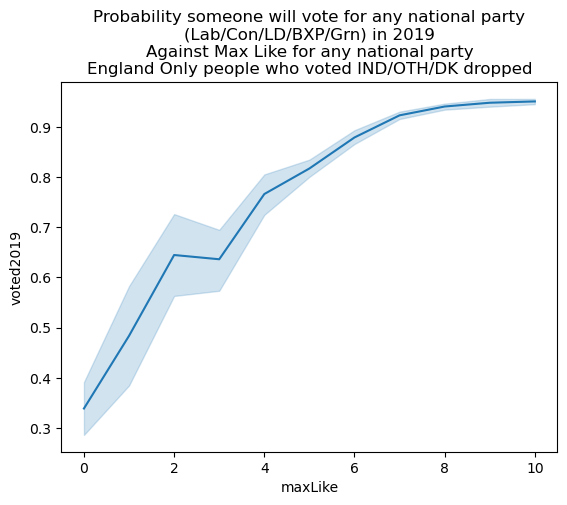

In [359]:
voted_for_listed_party = BES_Panel["p_past_vote_2019"].isin(['Conservative', 'Labour', 'Liberal Democrat',
        'Green Party', 
       'Brexit Party/Reform UK', ])

voting_2019_df = BES_Panel[search(BES_Panel,"like(Lab|Con|LD|BrexitParty|Grn)W19").index]
voting_2019_df["voted2019"] = (~NonVoter2019).astype('float')
voting_2019_df.loc[voting_2019_df["voted2019"].astype(bool)&(~voted_for_listed_party),"voted2019"]=np.nan
voting_2019_df["England2019"] = England2019
voting_2019_df["maxLike"] = BES_Panel[search(BES_Panel,"like(Lab|Con|LD|BrexitParty|Grn)W19").index]\
    .apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan))\
    .max(axis=1)
sns.lineplot(data = voting_2019_df[England2019],x="maxLike",y="voted2019");
plt.title("Probability someone will vote for any national party\n(Lab/Con/LD/BXP/Grn) in 2019\nAgainst Max Like for any national party\nEngland Only people who voted IND/OTH/DK dropped")

In [111]:
# BES_Panel[search(BES_Panel,"like(Lab|Con|LD|BrexitParty|Grn)W19").index].max(axis=1)

In [ ]:
### most important issue

### is it the case that people who choose "Immigration" simply lack competing alternatives? (now that crime is so low)

# selfPriorities 17/20, small_mii_cat, mii_cat, LRAL_mii_cat, (1-25)

In [368]:
search(BES_Panel,"^selfPriorities")#.tail(50)

selfPriorities_econW17           8663
selfPriorities_brexitW17         8663
selfPriorities_nhsW17            8663
selfPriorities_immigW17          8663
selfPriorities_crimeW17          8663
selfPriorities_environmentW17    8663
selfPriorities_noneW17           8663
selfPriorities_econW20           7900
selfPriorities_brexitW20         7900
selfPriorities_nhsW20            7900
selfPriorities_immigW20          7900
selfPriorities_crimeW20          7900
selfPriorities_environmentW20    7900
selfPriorities_noneW20           7900
dtype: int64

In [370]:
BES_Panel["mii_catW25"].value_counts()

mii_catW25
Living costs                9415
Economy-general             4783
Immigration                 3143
Inflation                   2100
Health                      1621
Environment                 1549
Pol-neg                      771
Europe                       604
Poverty                      503
Partisan-neg                 489
Housing                      327
Crime                        315
Inequality                   312
War                          278
Foreign affairs              197
Uncoded                      172
Morals                       132
Asylum                       100
Defence                       91
Taxation                      83
Education                     81
Pol values-auth               74
Austerity                     72
Transport/infrastructure      68
Pol values-liberal            63
Nat ident, goals-loss         59
Pol values-left               58
Unemployment                  52
Gender/sexuality/family       46
Welfare                       42

In [371]:
BES_Panel["small_mii_catW25"].value_counts()

small_mii_catW25
Economy               16467
Immigration            3243
Health                 1654
Environment            1549
Negativity             1289
Other lib-auth         1272
Inequality             1142
Europe                  604
Austerity/spending      303
Other                   124
Other left-right         77
Terrorism                23
Name: count, dtype: int64

In [372]:
search(BES_Panel,"likeCorbyn|likeBrexit")

likeCorbynW7           30895
likeCorbynW8           33502
likeCorbynW9           30036
likeCorbynW10          30237
likeCorbynW11          30956
likeCorbynW12          34394
likeCorbynW13          31135
likeCorbynW14          31063
likeCorbynW15          30842
likeBrexitPartyW15     30842
likeCorbynW16          37959
likeBrexitPartyW16     37959
likeCorbynW17          34366
likeBrexitPartyW17     34366
likeCorbynW18          37825
likeBrexitPartyW18     37825
likeCorbynW19          32177
likeBrexitPartyW19     32177
likeBrexitPartyW20     31468
likeBrexitPartyW21     30281
likeBrexitPartyW22     28113
likeBrexitPartyW23     30949
likeCorbynFormerW25    30407
likeBrexitPartyW25     30407
dtype: int64

In [374]:
BES_Panel[["likeCorbynW19","likeBrexitPartyW19"]]\
    .apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan))\
    .corr()

,likeCorbynW19,likeBrexitPartyW19
likeCorbynW19,1.000000,-0.395904
likeBrexitPartyW19,-0.395904,1.000000


In [ ]:
BES_Panel[["likeCorbynW19","likeBrexitPartyW19"]]\
    .apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan))\
    .corr()

In [385]:
like_list = [x for x in search(BES_Panel,"like.*W19").index if x not in ["likePriceW19","likePCW19","likelyBrexitW19"]]

In [386]:
BES_Panel[like_list]\
    .apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan))\
    .corr()["likeCorbynW19"].sort_values()

likeConW19           -0.574651
likeJohnsonW19       -0.541910
likeBrexitPartyW19   -0.395904
likeFarageW19        -0.382009
likeDaveyW19          0.228350
likeSwinsonW19        0.242653
likeLDW19             0.262229
likePhillipsW19       0.272513
likeMoranW19          0.356061
likeBartleyW19        0.376753
likeBerryW19          0.463493
likeGrnW19            0.488496
likeStarmerW19        0.492916
likeSNPW19            0.534901
likeSturgeonW19       0.546211
likeRaynerW19         0.579758
likeLongBaileyW19     0.635796
likeLabW19            0.791862
likeCorbynW19         1.000000
Name: likeCorbynW19, dtype: float64

In [ ]:
BES_Panel["likeBrexitPartyW25"]

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
 [Text(0, 0, 'Strongly dislike'),
  Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, 'Strongly like'),
  Text(11, 0, "Don't know")])

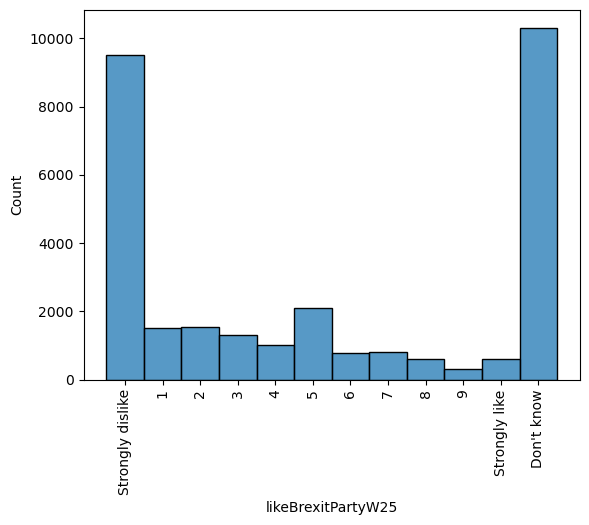

In [391]:
sns.histplot(BES_Panel["likeBrexitPartyW25"]);
plt.xticks(rotation=90)

<Axes: xlabel='likeFarageW19', ylabel='Count'>

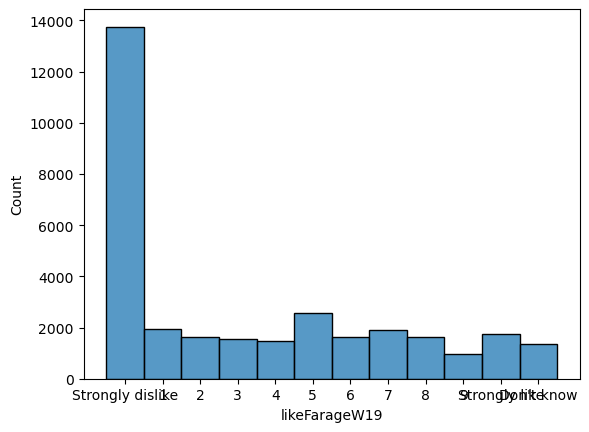

In [395]:
sns.histplot(BES_Panel["likeFarageW19"])

In [400]:
Faragists = BES_Panel["likeFarageW19"].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)>6

In [ ]:
######################################

In [45]:
df_var[ (df_var["party"]=="BrexitParty") & (df_var["type"]=="like") & (df_var["wave"]==30) ]

,fit_result,r_squared,c1,c2,c3,wave,type,party,max_pos_x,max_pos_y,max_val,N
likeBrexitPartyW30,\nParameter Value Standard Deviation\nc...,0.966687,0.49961,0.143774,3.160414,30.0,like,BrexitParty,7.0,10.0,6.608911,20635.0


In [469]:
df_var#[["c1","c2","c3","steepness","angle","fit_result"]]

,fit_result,r_squared,c1,c2,c3,wave,type,party,max_pos_x,max_pos_y,max_val,min_val,N,steepness,angle,date_friendly,date
likeConW1,\nParameter Value Standard Deviation\nc...,0.333096,0.969393,2.634426,3.443713,1.0,like,Con,10.0,10.0,7.047531,-0.160105,14636.0,2.807120,20.202161,2014: Spring,2014-02-01
likeLabW1,\nParameter Value Standard Deviation\nc...,0.109818,-0.877118,-1.244865,3.933303,1.0,like,Lab,0.0,0.0,6.055286,1.811320,14634.0,1.522835,-144.831891,2014: Spring,2014-02-01
likeLDW1,\nParameter Value Standard Deviation\nc...,0.049976,-0.619233,0.668839,2.835090,1.0,like,LD,10.0,0.0,4.123162,1.547017,14584.0,0.911480,-42.794547,2014: Spring,2014-02-01
likeUKIPW1,\nParameter Value Standard Deviation\nc...,0.189457,2.047210,0.659433,3.167806,1.0,like,UKIP,10.0,10.0,5.874448,0.461164,14137.0,2.150795,72.145578,2014: Spring,2014-02-01
likeSNPW1,\nParameter Value Standard Deviation\nc...,0.101197,-0.708974,-1.688648,3.946602,1.0,like,SNP,0.0,0.0,6.344225,1.548979,2819.0,1.831442,-157.225042,2014: Spring,2014-02-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ptvLDW30,\nParameter Value Standard Deviation\nc...,0.095749,-1.668674,-0.195804,3.714756,30.0,ptv,LD,0.0,0.0,5.579234,1.850278,5124.0,1.680123,-96.692528,2025: Spring,2025-05-01
ptvBrexitPartyW30,\nParameter Value Standard Deviation\nc...,0.210156,2.961709,0.734511,3.286645,30.0,ptv,BrexitParty,10.0,10.0,6.982864,-0.409575,5188.0,3.051430,76.071529,2025: Spring,2025-05-01
ptvSNPW30,\nParameter Value Standard Deviation\nc...,0.160128,-1.735458,-1.609433,3.435502,30.0,ptv,SNP,0.0,0.0,6.780393,0.090611,546.0,2.366873,-132.842292,2025: Spring,2025-05-01
ptvPCW30,\nParameter Value Standard Deviation\nc...,0.149698,-1.753583,-1.153140,3.507433,30.0,ptv,PC,0.0,0.0,6.414156,0.600711,332.0,2.098758,-123.328552,2025: Spring,2025-05-01


In [484]:

df_var[["c1","c2","c3","steepness","angle"]].to_pickle( "df_var.zip" , compression='zip' )
# ,"fit_result"

In [287]:
current_party = "ptvGrnW30"
df_var.loc[current_party]["fit_result"].params.copy()

OrderedDict([('c1', -1.7410334463663186),
             ('c2', -1.2068945665156112),
             ('c3', 3.18018388285181)])

In [293]:
from collections import OrderedDict
od = OrderedDict()
od['c1'] = df_var.loc[current_party]["c1"]
od['c2'] = df_var.loc[current_party]["c2"]
od['c3'] = df_var.loc[current_party]["c3"]
od

OrderedDict([('c1', -1.7410334463663186),
             ('c2', -1.2068945665156112),
             ('c3', 3.18018388285181)])

In [294]:
df_var.loc[current_party]["c1"]

-1.7410334463663186

In [295]:
od['c1'] =-2

In [467]:
df_var_temp

,c1,c2,c3,steepness,angle
likeConW1,0.969393,2.634426,3.443713,2.807120,20.202161
likeLabW1,-0.877118,-1.244865,3.933303,1.522835,-144.831891
likeLDW1,-0.619233,0.668839,2.835090,0.911480,-42.794547
likeUKIPW1,2.047210,0.659433,3.167806,2.150795,72.145578
likeSNPW1,-0.708974,-1.688648,3.946602,1.831442,-157.225042
...,...,...,...,...,...
ptvLDW30,-1.668674,-0.195804,3.714756,1.680123,-96.692528
ptvBrexitPartyW30,2.961709,0.734511,3.286645,3.051430,76.071529
ptvSNPW30,-1.735458,-1.609433,3.435502,2.366873,-132.842292
ptvPCW30,-1.753583,-1.153140,3.507433,2.098758,-123.328552


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W

In [135]:
like_waves(30,"ptv").value_counts()

REFUK    12119
LAB      11830
CON       8572
LD        7348
GP         131
Name: count, dtype: int64

In [250]:
from symfit import Poly, variables, parameters, Model, Fit

granularity = 200

x, y, z = variables('x, y, z')
c1, c2, c3 = parameters('c1, c2, c3')
# Make a polynomial. Note the `as_expr` to make it symfit friendly.
model_dict = {
    z: Poly( {(1, 0): c1, (0, 1): c2, (0,0):c3 }, x ,y).as_expr()
}
model = Model(model_dict)

# Generate example data
x_vec = np.linspace(-1, 1, num=granularity)
y_vec = np.linspace(-1, 1, num=granularity)
xdata, ydata = np.meshgrid(x_vec, y_vec)

zdata = model(x=xdata, y=ydata, c1=1.0, c2=2.0,c3=0.0).z

# Perform the fit
fit = Fit(model, x=xdata, y=ydata, z=zdata)
fit_result = fit.execute()
zfit = model(x=xdata, y=ydata, **fit_result.params).z
max_wave=30

## 1 and 1 missing wave only - W24 for BrexitParty!!!!
## don't obsess!

like_fit_df_waves = pd.DataFrame()

like_or_ptv="like"

for wave in range(1,max_wave+1):
    # if wave == 24: # such offend
    #     continue
    # like_fit_df = pd.DataFrame()
    # if wave>=15:
    #     party_list =[ x + "W"+str(wave) for x in  [ 'likeCon', 'likeLab',  'likeLD', 'likeBrexitParty',  'likeGrn', ] ]
    # else: 
    #     party_list =[ x + "W"+str(wave) for x in  [ 'likeCon', 'likeLab',  'likeLD', 'likeUKIP',  'likeGrn', ] ]
    # for party_var in party_list:
    #     zfit = model(x=xdata, y=ydata, **df_var.loc[party_var]["fit_result"].params).z
    #     like_fit_df[party_var] = zfit.flatten()

    # like_fit_df_waves[wave] = like_fit_df.idxmax(axis=1).apply(lambda x: x.split("W")[0])
    
    like_fit_df_waves[wave] = like_waves(wave,like_or_ptv)
print(fit_result)

# fig, (ax1, ax2) = plt.subplots(1, 2)
# sns.heatmap(zdata, ax=ax1)
# sns.heatmap(zfit, ax=ax2)
# plt.show()


Parameter Value        Standard Deviation
c1        1.000000e+00 2.264561e-19
c2        2.000000e+00 2.264561e-19
c3        4.283955e-17 1.313999e-19
Status message         Optimization terminated successfully.
Number of iterations   6
Objective              <symfit.core.objectives.LeastSquares object at 0x000001BDABEEC760>
Minimizer              <symfit.core.minimizers.BFGS object at 0x000001BDABEEC1C0>

Goodness of fit qualifiers:
chi_squared            2.7623402543758456e-29
objective_value        1.3811701271879228e-29
r_squared              1.0


In [56]:
# BES_Panel["likeGrnW24"]
# search(BES_Panel,"likeGrn")

In [252]:

zfit.shape
# CON and Brexit party sometimes go sub zero

(200, 200)

In [ ]:
    #     img = hv.Image(np.flip(res/len(colour_list), 0), bounds=(X.min(), Y.min(), X.max(), Y.max())).options(
    #                                                                       normalize=False,
    #                                                                       cmap=cmap,
    #                                                                       title=patchwork_title_text+overall_N_equal_text,
    #                                                                       xlabel=x_axis_label,
    #                                                                       ylabel=y_axis_label,
    #                                                                       xticks = locator,
    #                                                                       yticks = locator,            
    # #                                                                       invert_yaxis=True,
    #                                                                       #colorbar=True,
    #                                                                       interpolation=None,
    #                                                                       clabel=scale_text,
    #                                                                       fig_inches=(12,8),
    #                                                                       fontsize = fs_dict,
    #                                                                       hooks=[hook],
    #                                                                       ).redim.range(z=(0.0, 1.0))    
    #     hv_dict["all_ptv_surfaces"+"_by_PC_territory"+wave] = img

0           GP
1           GP
2           GP
3           GP
4           GP
         ...  
39995    REFUK
39996    REFUK
39997    REFUK
39998    REFUK
39999    REFUK
Name: 30, Length: 40000, dtype: object

In [253]:
import matplotlib as mpl
import matplotlib.patches as mpatches
scale = 50
padding =30


colors = ['blue','red', 'orange', 'cyan', 'green', ]
bounds = [0,1,2,3,4]
cmap = mpl.colors.ListedColormap(colors)
replace_dict = {'CON':0, 'LAB':1, 'LD':2, 'REFUK':3, 'GP':4}

wave = 30
like_or_ptv = "like"
like_numpy = like_waves(wave,like_or_ptv)
if like_numpy is not None:

    pol_comp_image = like_fit_df_waves[wave].replace(replace_dict).values.reshape((200, 200)).T
    
    
    ax = plt.imshow(pol_comp_image, interpolation='none', cmap=cmap,origin='lower');
    xlabel = "Economic: Left (0) - Right (50)"
    ylabel = "Social: Liberal (0) - Auth (50)"
    plt.xlabel(xlabel);
    plt.ylabel(ylabel);
    
    # if wave>=15:
    #     party_list =[ x + "W"+str(wave) for x in  [ 'likeCon', 'likeLab',  'likeLD', 'likeBrexitParty',  'likeGrn', ] ]
    # else: 
    #     party_list =[ x + "W"+str(wave) for x in  [ 'likeCon', 'likeLab',  'likeLD', 'likeUKIP',  'likeGrn', ] ]
    
    party_list = ["CON","LAB","LD","REFUK","GP"]
    for party_var in party_list:
        current_party = get_current_party(party_var,wave,like_or_ptv)
        
        party_vec_x = df_var.loc[current_party]["fit_result"].params['c2']
        party_vec_y = df_var.loc[current_party]["fit_result"].params['c1']
    
        # print(party_var,party_vec_x,party_vec_y)
        
        
        x_tail = (scale/2) + padding* (party_vec_x/np.sqrt((party_vec_x**2)+(party_vec_y**2)))
        y_tail = (scale/2) + padding* (party_vec_y/np.sqrt((party_vec_x**2)+(party_vec_y**2)))
        
        dx = scale*party_vec_x
        dy = scale*party_vec_y
        
        
        arrow = mpatches.FancyArrowPatch((x_tail, y_tail), (x_tail+dx, y_tail+dy),
                                         mutation_scale=50,color=colors[replace_dict[party_var]])
        plt.gca().add_patch(arrow)
    
    plt.xlim([-padding,scale+padding]);
    plt.ylim([-padding,scale+padding]);

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W

In [275]:
like_or_ptv

Dimension('like_or_ptv')

In [274]:
layout = get_likePolComp(wave, party_list,like_or_ptv)
print(layout)

TypeError: unsupported operand type(s) for +: 'Dimension' and 'str'

In [334]:
import matplotlib as mpl
# hv.extension('matplotlib')
colors = ['blue','red', 'orange', 'cyan', 'green', ]
# color_dict = {0:'blue',1:'red',2:'orange',3:'cyan',4:'green', }
cmap = mpl.colors.ListedColormap(colors)
replace_dict = {'CON':0, 'LAB':1, 'LD':2, 'REFUK':3, 'GP':4}

xlabel = "Economic: Left (0) - Right (50)"
ylabel = "Social: Liberal (0) - Auth (50)"
max_wave=30
image_dict=  {}
like_or_ptv = "ptv"
for wave in range(1,max_wave+1):

    party_list = ["CON","LAB","LD","REFUK","GP"]
    pol_comp = get_likePolComp(wave, party_list,like_or_ptv)
    if pol_comp:
        image_dict[wave] = pol_comp

hmap = hv.HoloMap(image_dict, kdims='wave')
hmap




<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W

TypeError: list.remove() takes exactly one argument (0 given)

:HoloMap   [wave]
   :Layout
      .Bars.I  :Bars   [parties]   (voteshare,colour)
      .Image.I :Image   [x,y]   (z)

:Bars   [parties]   (voteshare,colour)
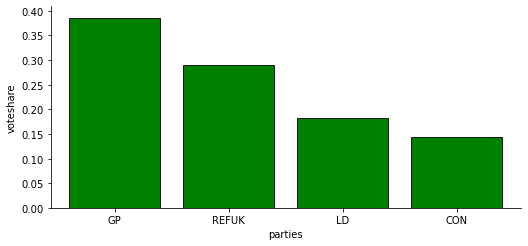

In [357]:
vote_share = like_numpy.value_counts(normalize=True).reset_index()
vote_share["colour"] = vote_share["index"].replace(palette_dict)
# vote_share["proportion"] = vote_share["proportion"]*100
vote_share.columns = ["parties","voteshare","colour"]

# hv.Bars(vote_share,color='colour')
vote_share.hvplot.bar(x="parties",y="voteshare",color="colour")
        # pol_comp = pol_comp# + vote_share.hvplot.bar(x="parties",y="voteshare",color="colour")

In [370]:
palette_dict = {"CON":'blue',"LAB":'red',"LD":'orange',"REFUK":'cyan',"SNP":"yellow",'PC':"olive",'GP':"green",
                }

vote_share = like_numpy.value_counts(normalize=True).reset_index()
replace_dict = {'CON':0, 'LAB':1, 'LD':2, 'REFUK':3, 'GP':4}
vote_share["colour"] = vote_share["index"].replace(replace_dict)
#.replace(palette_dict)

vote_share.hvplot.bar(x="index",y="proportion",
                      cmap=cmap,
                      
                      # color=palette_dict.values()
                     ).opts(color='colour')

ValueError: 'facecolor' or 'color' argument must be a valid color orsequence of colors.

:Bars   [index]   (proportion)

In [463]:
df_var

,fit_result,r_squared,c1,c2,c3,wave,type,party,max_pos_x,max_pos_y,max_val,min_val,N,steepness,angle,date_friendly,date
likeConW1,\nParameter Value Standard Deviation\nc...,0.333096,0.969393,2.634426,3.443713,1.0,like,Con,10.0,10.0,7.047531,-0.160105,14636.0,2.807120,20.202161,2014: Spring,2014-02-01
likeLabW1,\nParameter Value Standard Deviation\nc...,0.109818,-0.877118,-1.244865,3.933303,1.0,like,Lab,0.0,0.0,6.055286,1.811320,14634.0,1.522835,-144.831891,2014: Spring,2014-02-01
likeLDW1,\nParameter Value Standard Deviation\nc...,0.049976,-0.619233,0.668839,2.835090,1.0,like,LD,10.0,0.0,4.123162,1.547017,14584.0,0.911480,-42.794547,2014: Spring,2014-02-01
likeUKIPW1,\nParameter Value Standard Deviation\nc...,0.189457,2.047210,0.659433,3.167806,1.0,like,UKIP,10.0,10.0,5.874448,0.461164,14137.0,2.150795,72.145578,2014: Spring,2014-02-01
likeSNPW1,\nParameter Value Standard Deviation\nc...,0.101197,-0.708974,-1.688648,3.946602,1.0,like,SNP,0.0,0.0,6.344225,1.548979,2819.0,1.831442,-157.225042,2014: Spring,2014-02-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ptvLDW30,\nParameter Value Standard Deviation\nc...,0.095749,-1.668674,-0.195804,3.714756,30.0,ptv,LD,0.0,0.0,5.579234,1.850278,5124.0,1.680123,-96.692528,2025: Spring,2025-05-01
ptvBrexitPartyW30,\nParameter Value Standard Deviation\nc...,0.210156,2.961709,0.734511,3.286645,30.0,ptv,BrexitParty,10.0,10.0,6.982864,-0.409575,5188.0,3.051430,76.071529,2025: Spring,2025-05-01
ptvSNPW30,\nParameter Value Standard Deviation\nc...,0.160128,-1.735458,-1.609433,3.435502,30.0,ptv,SNP,0.0,0.0,6.780393,0.090611,546.0,2.366873,-132.842292,2025: Spring,2025-05-01
ptvPCW30,\nParameter Value Standard Deviation\nc...,0.149698,-1.753583,-1.153140,3.507433,30.0,ptv,PC,0.0,0.0,6.414156,0.600711,332.0,2.098758,-123.328552,2025: Spring,2025-05-01


:DynamicMap   [Con_angle,Lab_angle,Ld_angle,Refuk_angle,Gp_angle,Con_c3,Lab_c3,Ld_c3,Refuk_c3,Gp_c3,fw_wave,like_or_ptv]
   :Overlay
      .Image.I      :Image   [x,y]   (z)
      .Polygons.I   :Polygons   [x,y]
      .Polygons.II  :Polygons   [x,y]
      .Polygons.III :Polygons   [x,y]
      .Polygons.IV  :Polygons   [x,y]
      .Polygons.V   :Polygons   [x,y]
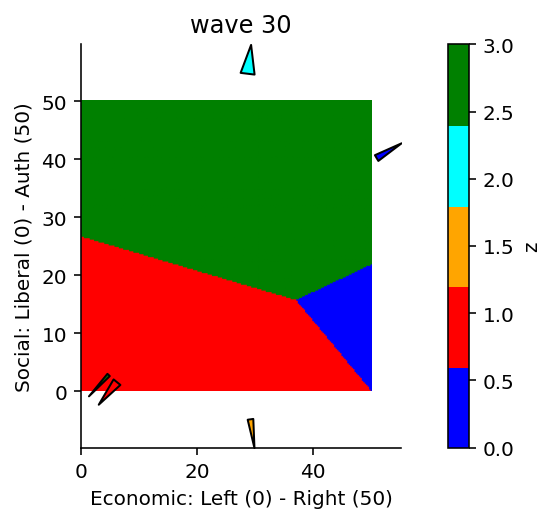

In [490]:
df_var[["c1","c2","c3","steepness","angle"]][["VI" in x for x in df_var.index]].describe()

,c1,c2,c3,steepness,angle
count,149.000000,149.000000,149.000000,149.000000,149.000000
mean,0.070110,0.027208,0.450379,0.511914,-45.974857
std,0.411062,0.531096,0.345468,0.439205,96.298157
min,-0.618541,-1.138747,0.045089,0.034444,-161.882689
25%,-0.218694,-0.122996,0.141000,0.142747,-131.543563
50%,-0.078960,-0.037822,0.343555,0.348327,-76.618858
75%,0.393748,0.041785,0.724574,0.807133,41.646567
max,1.213843,1.396888,1.472563,1.780188,112.102997


In [491]:
df_var[["c1","c2","c3","steepness","angle"]][["like" in x for x in df_var.index]].describe()

,c1,c2,c3,steepness,angle
count,223.000000,223.000000,223.000000,223.000000,223.000000
mean,-0.318948,-0.248941,3.639158,1.953155,-64.548785
std,1.495352,1.352629,0.820596,0.630969,87.392524
min,-1.934859,-2.454884,0.702883,0.665900,-166.787980
25%,-1.427843,-1.178447,3.221830,1.522922,-130.662053
50%,-1.112962,-0.791747,3.891906,1.900755,-119.107434
75%,1.323509,0.578068,4.205149,2.406748,34.676667
max,2.810395,3.163732,5.178541,3.461420,94.774317


In [431]:
hv_panel = pn.panel(dmap)
print(hv_panel)

NameError: name 'pn' is not defined

ModuleNotFoundError: No module named 'Panel'

In [483]:
df_var_temp

,c1,c2,c3,steepness,angle
likeConW1,0.969393,2.634426,3.443713,2.807120,20.202161
likeLabW1,-0.877118,-1.244865,3.933303,1.522835,-144.831891
likeLDW1,-0.619233,0.668839,2.835090,0.911480,-42.794547
likeUKIPW1,2.047210,0.659433,3.167806,2.150795,72.145578
likeSNPW1,-0.708974,-1.688648,3.946602,1.831442,-157.225042
...,...,...,...,...,...
ptvLDW30,-1.668674,-0.195804,3.714756,1.680123,-96.692528
ptvBrexitPartyW30,2.961709,0.734511,3.286645,3.051430,76.071529
ptvSNPW30,-1.735458,-1.609433,3.435502,2.366873,-132.842292
ptvPCW30,-1.753583,-1.153140,3.507433,2.098758,-123.328552


:DynamicMap   [phase,frequency]
   :Curve   [x]   (y)
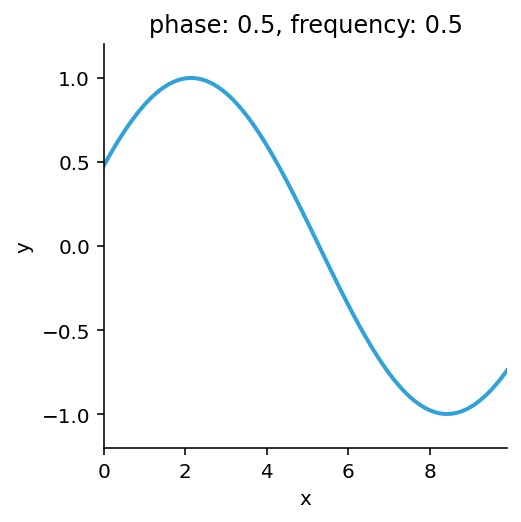

In [40]:
def sine_curve(phase, freq):
    xvals = [0.1* i for i in range(100)]
    return hv.Curve((xvals, [np.sin(phase+freq*x) for x in xvals]))

# When run live, this cell's output should match the behavior of the GIF below
dmap = hv.DynamicMap(sine_curve, kdims=['phase', 'frequency'])
dmap.redim.range(phase=(0.5,1), frequency=(0.5,1.25))

In [314]:
# hv.help(hv.Dimension)


In [176]:
import hvplot.pandas

In [8]:
%%time
## reformat data so we get gaps, waves, parties

df_wt = df[search(df,"wt").index].reset_index().melt(id_vars="id")
df_wt["wave"] = df_wt["variable"].apply(lambda x: int(x.split("wtW")[1]))
df_wt = df_wt.drop("variable",axis=1)
df_wt= df_wt.set_index(["id","wave"])
                                    

# not going to worry about weights at the moment
df_like_ptv_gap = pd.melt( df[search(df,"like_ptv_gap").index].reset_index(),id_vars="id" )
df_like_ptv_gap["party"] = df_like_ptv_gap["variable"].apply(lambda x: x.split("like_ptv_gap_")[1].split("W")[0])
df_like_ptv_gap["wave"] = df_like_ptv_gap["variable"].apply(lambda x: int(x.split("W")[1]))

df_like_ptv_gap = df_like_ptv_gap.set_index(["id","wave"])
df_like_ptv_gap["wt_ind"] = df_like_ptv_gap.index
df_like_ptv_gap["wt"] =df_wt.loc[df_like_ptv_gap["wt_ind"]]

df_like_ptv_gap = df_like_ptv_gap.drop("wt_ind",axis=1).reset_index()
df_like_ptv_gap=df_like_ptv_gap.dropna()

CPU times: total: 25.7 s
Wall time: 25.9 s


In [198]:
df_like_ptv_gap.hvplot.kde(y="value",groupby = ["party","wave"],bandwidth=.25)

:DynamicMap   [party,wave]
   :Distribution   [value]   (Density)

In [199]:
df_like_ptv_gap.groupby(["party","wave"])["value"].mean().reset_index().hvplot.line(x="wave",y='value',groupby="party")

:DynamicMap   [party]
   :Curve   [wave]   (value)

In [15]:
wave_to_date = BES_file_manifest[BES_file_manifest["Only_or_Combined"]=="Only"].set_index("Wave No")["Date_Start"]
wave_to_date.loc[26] = "Apr-24"
wave_to_date.loc[27] = "May-24"
wave_to_date.loc[28] = "Jun-24"
wave_to_date.loc[29] = "Jul-24"
wave_to_date.loc[30] = "May-25"
wave_to_date = pd.to_datetime(wave_to_date,format="%b-%y")
df_like_ptv_gap["date"] = df_like_ptv_gap["wave"].apply(lambda x: wave_to_date.loc[x])

CPU times: total: 21.3 s
Wall time: 21.6 s


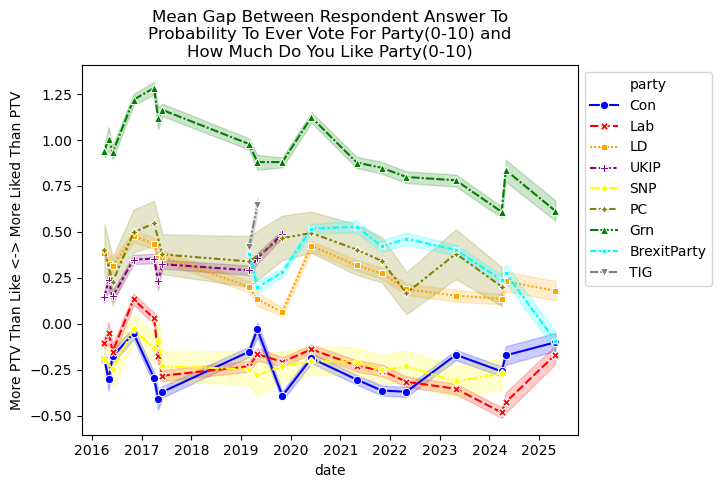

In [17]:
%%time
palette_dict = {"Con":'blue',"Lab":'red',"LD":'orange',"UKIP":'purple',"SNP":"yellow",'PC':"olive",'Grn':"green",
                'BNP':'black',"TIG":'grey',"DUP":'magenta','BrexitParty':'cyan'}
ax=sns.lineplot(data=df_like_ptv_gap,x="date",y="value",hue="party",palette=palette_dict,markers=True,style='party',weights="wt")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1));
plt.ylabel("More PTV Than Like <-> More Liked Than PTV");
plt.title("Mean Gap Between Respondent Answer To\nProbability To Ever Vote For Party(0-10) and\nHow Much Do You Like Party(0-10)");

In [203]:
df_var[["c1","c2","c3","steepness"]].describe()

,c1,c2,c3,steepness
count,410.000000,410.000000,410.000000,410.000000
mean,-0.401804,-0.309730,3.551375,2.104960
std,1.571554,1.493124,0.891314,0.717997
min,-2.227411,-2.716951,0.462807,0.501574
25%,-1.548349,-1.279039,3.165512,1.635114
50%,-1.194993,-0.891031,3.731351,2.115128
75%,1.255010,0.452691,4.193234,2.535857
max,2.961709,3.656878,5.178541,3.991912


In [ ]:
df_var[["c1","c2","c3","steepness"]].describe()

In [205]:
df_var['r_squared'].describe()

count    410.000000
mean       0.173852
std        0.087166
min        0.025622
25%        0.114815
50%        0.160079
75%        0.220616
max        0.439502
Name: r_squared, dtype: float64

In [220]:
mask = (df_var['r_squared']>.1) & (df_var['party'].isin(["Con","Lab","Grn","UKIP","BrexitParty"])) & (df_var["type"]=="like")
df_var[["c1","c2","c3","steepness"]][mask].describe()

,c1,c2,c3,steepness
count,124.000000,124.000000,124.000000,124.000000
mean,0.256035,0.152597,3.665354,2.276135
std,1.735453,1.544175,0.761074,0.512759
min,-1.879018,-2.181232,1.702334,1.505750
25%,-1.491684,-1.162582,3.165819,1.861942
50%,0.985850,0.350072,3.958445,2.181256
75%,1.998579,0.771861,4.270925,2.618200
max,2.810395,3.163732,4.861250,3.461420


In [229]:
df_var[["c1","c2","c3","steepness","angle","party"]][mask].groupby("party").mean()

,c1,c2,c3,steepness,angle
party,,,,,
BrexitParty,2.117722,0.632992,2.639801,2.211271,73.065401
Con,1.600196,2.471545,3.765726,2.978157,32.917897
Grn,-1.584959,-1.054080,4.287151,1.907867,-123.654677
Lab,-1.385020,-1.432922,4.122549,2.006951,-135.882869
UKIP,2.164350,0.514327,2.611355,2.226179,76.688890


In [289]:
pan_dataset_values.isnull().sum()

Economic: Left(0) <-> Right(200){uniform}                          2513
Social: Liberalism(0) <-> Conservatism(200){uniform}               2513
Economic: Left <-> Right{gaussian-ish}                             2513
Social: Liberalism <-> Conservatism{gaussian-ish}                  2513
Economic: Left <-> Right{gaussian-ish}completish                   2254
Economic: Left <-> Right{gaussian-ish}complete                      816
Social: Liberalism <-> Conservatism{gaussian-ish}completish        2174
Social: Liberalism <-> Conservatism{gaussian-ish}complete           736
Economic: Left <-> Right{gaussian-ish}complete_fully                  0
Social: Liberalism <-> Conservatism{gaussian-ish}complete_fully       0
dtype: int64